# Import

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from catboost import CatBoostRegressor
from cuml.ensemble import RandomForestRegressor as cuRF
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.inspection import PartialDependenceDisplay
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OneHotEncoder

/home/reesarosyid/Documents/Battery/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Config

In [2]:
DATA_PATH = "../Dataset/Dataset_Li.csv"
TARGET = "dV_percent"
UNIT = "%"
DV_MAX = 500                # rows with dV% above this are dropped
SG_AS_CATEGORY = False      # treat space group columns as categorical

RANDOM_STATE = 42
TEST_SIZE = 0.2
K = 10
SHAP_SAMPLE = 3_000
PDP_TOP_N = 5
PDP_SAMPLE = 5_000
PDP_ICE_LINES = 200
AD_FIT_SAMPLE = 50_000
AD_KNN = 5
AD_PERCENTILE = 95
RF_TUNE_SAMPLE = 150_000    # random forest is tuned on a subsample

# same folds for baseline, grid search and tuned models
kf = KFold(n_splits=K, shuffle=True, random_state=RANDOM_STATE)

SCORING = {
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "R2": "r2",
}

ACCENT = "#4A7EBB"
GRID = "#D8DCE0"
TEXT = "#22262B"
SPINE = "#5C6370"
BASE_COLOR = "#B4442E"
TUNED_COLOR = ACCENT
DENSITY_CMAP = "Blues"

MAX_TITLE = 34
P_LOW, P_HIGH = 0.01, 0.99
TRIM_PRED_AXES = True


def style_axes(ax, grid_axis="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=8, colors=SPINE, length=0)


def short_names(names):
    """'XGBoost (boosting)' -> 'XGBoost'"""
    return pd.Index(names).str.replace(r"\s*\(.*\)", "", regex=True)


def truncate(label):
    return label if len(label) <= MAX_TITLE else label[:MAX_TITLE - 3] + "..."


def trimmed_limits(values, pad_frac=0.05):
    low, high = np.quantile(values, [P_LOW, P_HIGH])
    pad = (high - low) * pad_frac
    return low - pad, high + pad


def feature_panels(data, plot_func, title, ncol=5):
    columns = data.select_dtypes("number").columns
    nrow = (len(columns) + ncol - 1) // ncol

    fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow))
    axes = axes.ravel()

    for ax, column in zip(axes, columns):
        values = data[column].dropna()
        ax.set_title(truncate(column), fontsize=8.5, color=TEXT)
        plot_func(ax, values, values.min(), values.max())
        style_axes(ax)

    for ax in axes[len(columns):]:
        ax.axis("off")

    fig.suptitle(title, fontsize=13, color=TEXT)
    fig.tight_layout()
    plt.show()


def draw_boxplot(ax, values, low, high):
    ax.boxplot(
        values,
        widths=0.55,
        showfliers=True,
        medianprops={"color": ACCENT, "linewidth": 2},
        boxprops={"color": SPINE},
        whiskerprops={"color": SPINE},
        capprops={"color": SPINE},
    )
    ax.set_xticks([])
    if low < high:
        pad = (high - low) * 0.12
        ax.set_ylim(low - pad, high + pad)


def draw_histogram(ax, values, low, high):
    if low == high:
        ax.text(0.5, 0.5, f"Constant\n{values.iloc[0]:.4g}",
                ha="center", va="center", transform=ax.transAxes)
        ax.set_xticks([])
        ax.set_yticks([])
        return
    ax.hist(values.clip(low, high), bins=50, range=(low, high),
            color=ACCENT, edgecolor="white", linewidth=0.4)


def plot_correlation(data, method="spearman"):
    """Lower-triangular correlation heatmap. Returns the correlation matrix."""
    corr = data.select_dtypes(include="number").corr(method=method)
    n = len(corr)
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

    fig, ax = plt.subplots(figsize=(0.9 * n + 3, 0.9 * n + 1))
    heatmap = ax.imshow(np.ma.masked_where(mask, corr), cmap="coolwarm", vmin=-1, vmax=1)

    for i in range(n):
        for j in range(i + 1):
            value = corr.iloc[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(value) > 0.6 else TEXT)

    labels = [c.replace("MagpieData ", "") for c in corr.columns]
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(labels, fontsize=8)
    ax.tick_params(colors=SPINE, length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

    bar = fig.colorbar(heatmap, ax=ax, shrink=0.6, ticks=[-1, -0.5, 0, 0.5, 1])
    bar.set_label(f"{method.title()} Correlation", fontsize=9, color=SPINE)
    bar.ax.tick_params(labelsize=8, colors=SPINE, length=0)
    bar.outline.set_visible(False)

    ax.set_title(f"{method.title()} Correlation Matrix", fontsize=13, color=TEXT, pad=14)
    fig.tight_layout()
    plt.show()
    return corr


def summarize_correlation(corr, target, threshold=0.8):
    target_corr = corr[target].drop(target).sort_values(key=np.abs, ascending=False)

    print(f"Correlation with '{target}':")
    for name, value in target_corr.items():
        print(f"  {value:+.3f}  {name}")

    features = corr.drop(index=target, columns=target).abs()
    upper = np.triu(np.ones(features.shape, dtype=bool), k=1)
    pairs = features.where(upper).stack().sort_values(ascending=False)
    pairs = pairs[pairs > threshold]

    print(f"\nFeature pairs with |correlation| > {threshold}:")
    if pairs.empty:
        print("  None")
    for (left, right), value in pairs.items():
        print(f"  {value:.3f}  {left} <-> {right}")

    return target_corr, pairs


def plot_target_correlation(corr, target):
    target_corr = corr[target].drop(target).dropna().sort_values(key=np.abs)
    labels = [c.replace("MagpieData ", "") for c in target_corr.index]
    colors = plt.cm.coolwarm((target_corr.to_numpy() + 1) / 2)

    fig, ax = plt.subplots(figsize=(8, 0.35 * len(target_corr) + 1.5))
    ax.barh(labels, target_corr, color=colors, height=0.7)
    ax.axvline(0, color=SPINE, linewidth=0.8)

    for y, value in enumerate(target_corr):
        ax.text(value + (0.01 if value >= 0 else -0.01), y, f"{value:+.2f}",
                ha="left" if value >= 0 else "right", va="center",
                fontsize=7.5, color=TEXT)

    ax.set_xlim(-1, 1)
    ax.set_xlabel("Correlation", fontsize=9, color=SPINE)
    style_axes(ax, grid_axis="x")
    ax.tick_params(axis="y", labelsize=8)
    ax.set_title(f"Feature correlation with {target}", fontsize=13, color=TEXT)
    fig.tight_layout()
    plt.show()


def cv_then_test(name, model, X_tr, y_tr, X_te, y_te, folds=kf):
    """K-fold CV on the training set, then refit on all of it and score the test set."""
    cv = cross_validate(model, X_tr, y_tr, cv=folds, scoring=SCORING,
                        n_jobs=1, error_score="raise")
    fold_rmse = -cv["test_RMSE"]
    fold_mae = -cv["test_MAE"]
    fold_r2 = cv["test_R2"]

    start = time.perf_counter()
    model.fit(X_tr, y_tr)
    elapsed = time.perf_counter() - start
    y_pred = np.asarray(model.predict(X_te))

    row = {
        "model": name,
        "CV RMSE": fold_rmse.mean(), "CV RMSE std": fold_rmse.std(),
        "CV MAE": fold_mae.mean(), "CV MAE std": fold_mae.std(),
        "CV R2": fold_r2.mean(), "CV R2 std": fold_r2.std(),
        "test RMSE": mean_squared_error(y_te, y_pred) ** 0.5,
        "test MAE": mean_absolute_error(y_te, y_pred),
        "test R2": r2_score(y_te, y_pred),
        "CV (s)": cv["fit_time"].sum(), "refit (s)": elapsed,
    }
    print(f"{name:<24} CV MAE={row['CV MAE']:.4f}+/-{row['CV MAE std']:.4f}  "
          f"CV RMSE={row['CV RMSE']:.4f}  CV R2={row['CV R2']:.4f}  |  "
          f"test MAE={row['test MAE']:.4f}  ({row['CV (s)']:.0f}s)")
    return row, y_pred


def evaluate_all(named_models, X_tr, y_tr, X_te, y_te, heading):
    rows, preds = [], {}
    for name, model in named_models.items():
        row, preds[name] = cv_then_test(name, model, X_tr, y_tr, X_te, y_te)
        rows.append(row)

    table = pd.DataFrame(rows).set_index("model").sort_values("CV MAE")
    print(f"\n{heading}, {K}-fold CV (sorted by CV MAE)")
    print(table.round(4).to_string())
    return table, preds


def plot_pred_vs_actual(ax, y_true, y_pred, low, high):
    """Hexbin of predicted vs actual with the ideal and fitted lines.

    Metrics and the fitted line use all rows, regardless of the axis limits.
    """
    slope, intercept = np.polyfit(y_true, y_pred, 1)
    line = np.array([low, high])

    hexes = ax.hexbin(y_true, y_pred, gridsize=45, extent=(low, high, low, high),
                      bins="log", cmap=DENSITY_CMAP, mincnt=1)
    ideal, = ax.plot(line, line, color=TEXT, ls="--", lw=1.2,
                     label="perfect prediction (predicted = actual)")
    fitted, = ax.plot(line, slope * line + intercept, color=BASE_COLOR, lw=1.8,
                      label="fitted line")

    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    ax.set_aspect("equal")
    style_axes(ax, grid_axis="both")

    metrics_text = (f"$R^2$ = {r2_score(y_true, y_pred):.2f}\n"
                    f"RMSE = {mean_squared_error(y_true, y_pred) ** 0.5:.2f} {UNIT}\n"
                    f"MAE = {mean_absolute_error(y_true, y_pred):.2f} {UNIT}")
    ax.text(0.04, 0.96, metrics_text, transform=ax.transAxes, va="top", ha="left",
            fontsize=10, color=TEXT,
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=GRID))
    return hexes, (ideal, fitted)

# Load Data

In [3]:
DV_FEATURES = [
    "chg__MagpieData mode Electronegativity",
    "x2_discharged",
    "x1_charged",
    "disch__MagpieData minimum Column",
    "charged_sg",
    "chg__MagpieData avg_dev GSvolume_pa",
    "chg__2-norm",
    "chg__MagpieData mode GSvolume_pa",
    "disch__MagpieData range SpaceGroupNumber",
    "disch__MagpieData mode GSvolume_pa",
    "chg__10-norm",
    "disch__MagpieData mode Electronegativity",
    "chg__MagpieData mean CovalentRadius",
    "disch__frac p valence electrons",
    "chg__MagpieData mean MendeleevNumber",
    "chg__5-norm",
    "disch__MagpieData range GSvolume_pa",
    "chg__7-norm",
    "disch__MagpieData minimum GSbandgap",
    "discharged_sg",
]

df = pd.read_csv(DATA_PATH)
df_dv = df[DV_FEATURES + [TARGET]].copy()
df_dv.head()

,chg__MagpieData mode Electronegativity,x2_discharged,x1_charged,disch__MagpieData minimum Column,charged_sg,chg__MagpieData avg_dev GSvolume_pa,chg__2-norm,chg__MagpieData mode GSvolume_pa,disch__MagpieData range SpaceGroupNumber,disch__MagpieData mode GSvolume_pa,...,disch__MagpieData mode Electronegativity,chg__MagpieData mean CovalentRadius,disch__frac p valence electrons,chg__MagpieData mean MendeleevNumber,chg__5-norm,disch__MagpieData range GSvolume_pa,chg__7-norm,disch__MagpieData minimum GSbandgap,discharged_sg,dV_percent
0,3.44,4.0,0.0,1.0,14.0,20.757733,0.663325,9.1050,217.0,9.1050,...,3.44,95.400000,0.583333,68.200000,0.600984,67.466667,0.600078,0.0,14,8.2847
1,3.16,8.0,0.0,1.0,62.0,1.779687,0.790569,24.4975,165.0,24.4975,...,3.16,118.000000,0.625000,71.000000,0.750616,12.650000,0.750049,0.0,139,17.3335
2,3.16,4.0,0.0,1.0,223.0,1.779687,0.790569,24.4975,165.0,24.4975,...,3.16,118.000000,0.625000,71.000000,0.750616,12.650000,0.750049,0.0,139,31.7455
3,1.00,2.0,0.0,1.0,139.0,6.613333,0.745356,37.7700,35.0,37.7700,...,1.00,164.333333,0.000000,27.333333,0.670782,21.176667,0.667408,0.0,225,20.0363
4,1.00,2.0,0.0,1.0,12.0,6.613333,0.745356,37.7700,35.0,37.7700,...,1.00,164.333333,0.000000,27.333333,0.670782,21.176667,0.667408,0.0,225,21.1352


In [4]:
df_dv.describe().T

,count,mean,std,min,25%,50%,75%,max
chg__MagpieData mode Electronegativity,850873.0,1.564367,0.729014,0.790000,0.980000,1.310000,1.910000,3.980000
x2_discharged,850873.0,5.855866,9.761767,1.000000,2.000000,4.000000,6.000000,1020.800000
x1_charged,850873.0,1.446617,2.803775,0.000000,0.000000,1.000000,2.000000,96.000000
disch__MagpieData minimum Column,850873.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
charged_sg,850200.0,116.649873,72.407147,1.000000,58.000000,129.000000,187.000000,230.000000
chg__MagpieData avg_dev GSvolume_pa,850873.0,5.526322,6.503465,0.000000,1.485000,3.265625,6.500000,55.062500
chg__2-norm,850873.0,0.707479,0.083380,0.459426,0.612372,0.707107,0.745356,1.000000
chg__MagpieData mode GSvolume_pa,850873.0,18.998658,11.557075,5.640000,13.640000,16.480000,22.570238,115.765000
disch__MagpieData range SpaceGroupNumber,850873.0,63.197076,72.874190,0.000000,4.000000,35.000000,77.000000,227.000000
disch__MagpieData mode GSvolume_pa,850873.0,17.707479,8.758323,5.640000,16.593333,16.593333,16.593333,115.765000


In [5]:
df_dv.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 850873 entries, 0 to 850872
Data columns (total 21 columns):
 #   Column                                    Non-Null Count   Dtype  
---  ------                                    --------------   -----  
 0   chg__MagpieData mode Electronegativity    850873 non-null  float64
 1   x2_discharged                             850873 non-null  float64
 2   x1_charged                                850873 non-null  float64
 3   disch__MagpieData minimum Column          850873 non-null  float64
 4   charged_sg                                850200 non-null  float64
 5   chg__MagpieData avg_dev GSvolume_pa       850873 non-null  float64
 6   chg__2-norm                               850873 non-null  float64
 7   chg__MagpieData mode GSvolume_pa          850873 non-null  float64
 8   disch__MagpieData range SpaceGroupNumber  850873 non-null  float64
 9   disch__MagpieData mode GSvolume_pa        850873 non-null  float64
 10  chg__10-norm        

# EDA
## Missing Values and Duplicates

In [6]:
missing = df_dv.isna().sum()
missing = missing[missing > 0]

print("Missing values per column:")
print(missing.to_string() if not missing.empty else "  none")

Missing values per column:
charged_sg    673


In [7]:
# duplicates are checked on features only: identical inputs with different
# targets could end up in both train and test
feature_cols = df_dv.columns.drop(TARGET)

print(f"Duplicate rows (features only): {df_dv.duplicated(subset=feature_cols).sum():,}")

Duplicate rows (features only): 2,105


In [8]:
df_dv = (
    df_dv
    .dropna()
    .drop_duplicates(subset=feature_cols, keep="first")
    .reset_index(drop=True)
)

print(f"rows remaining       : {len(df_dv):,}")
print(f"remaining NaN        : {int(df_dv.isna().sum().sum())}")
print(f"remaining duplicates : {int(df_dv.duplicated(subset=feature_cols).sum())}")

rows remaining       : 848,144
remaining NaN        : 0
remaining duplicates : 0


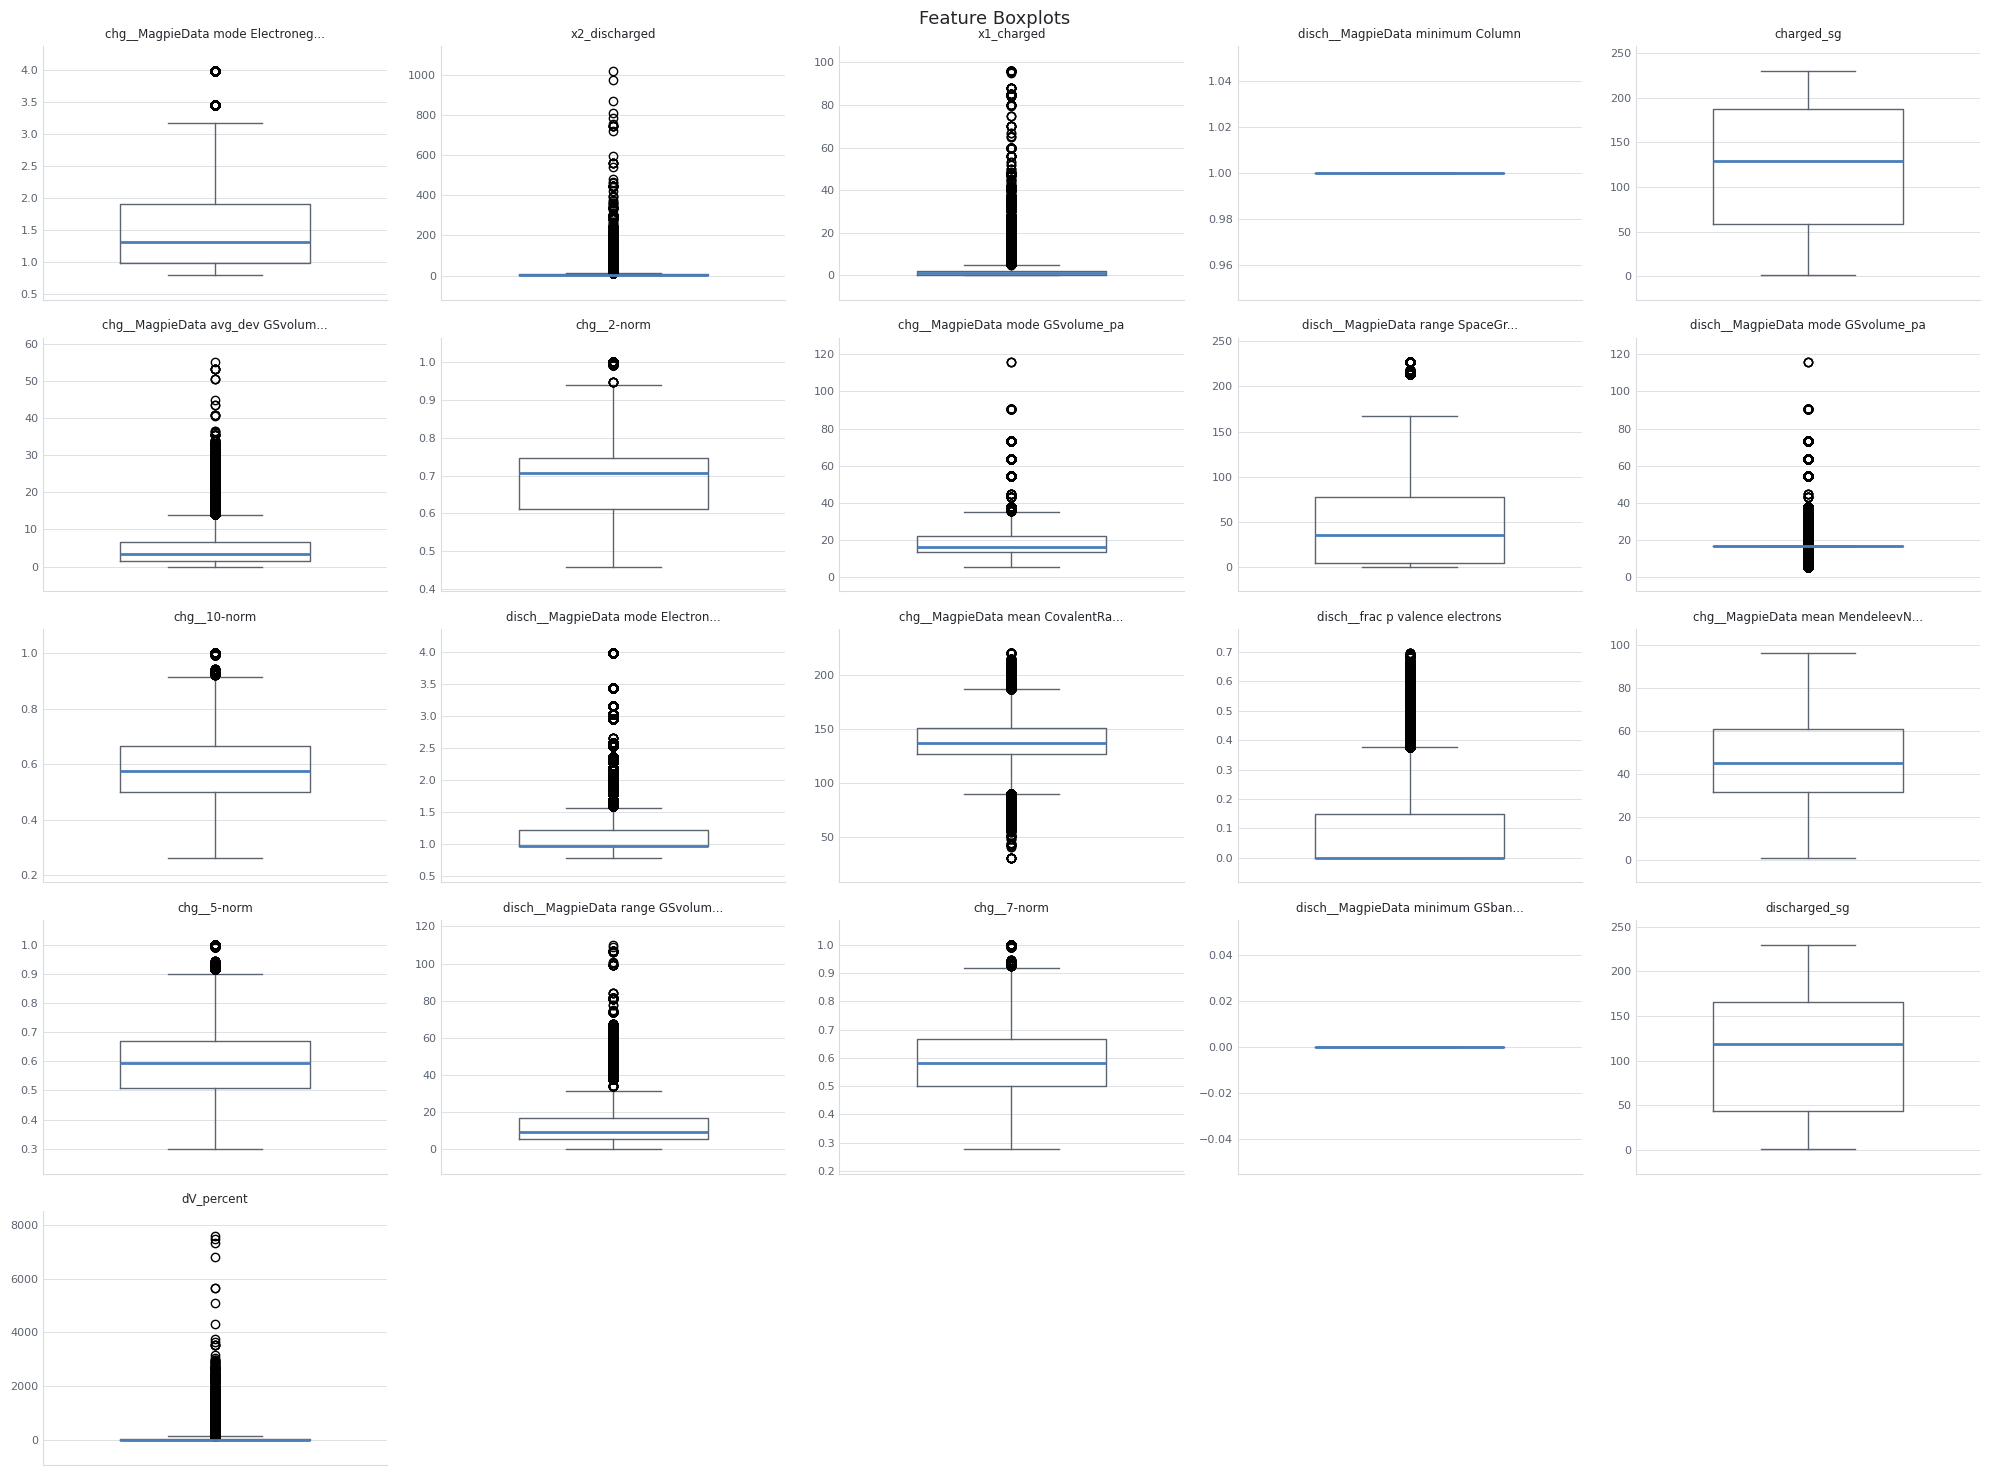

In [9]:
feature_panels(df_dv, draw_boxplot, "Feature Boxplots")

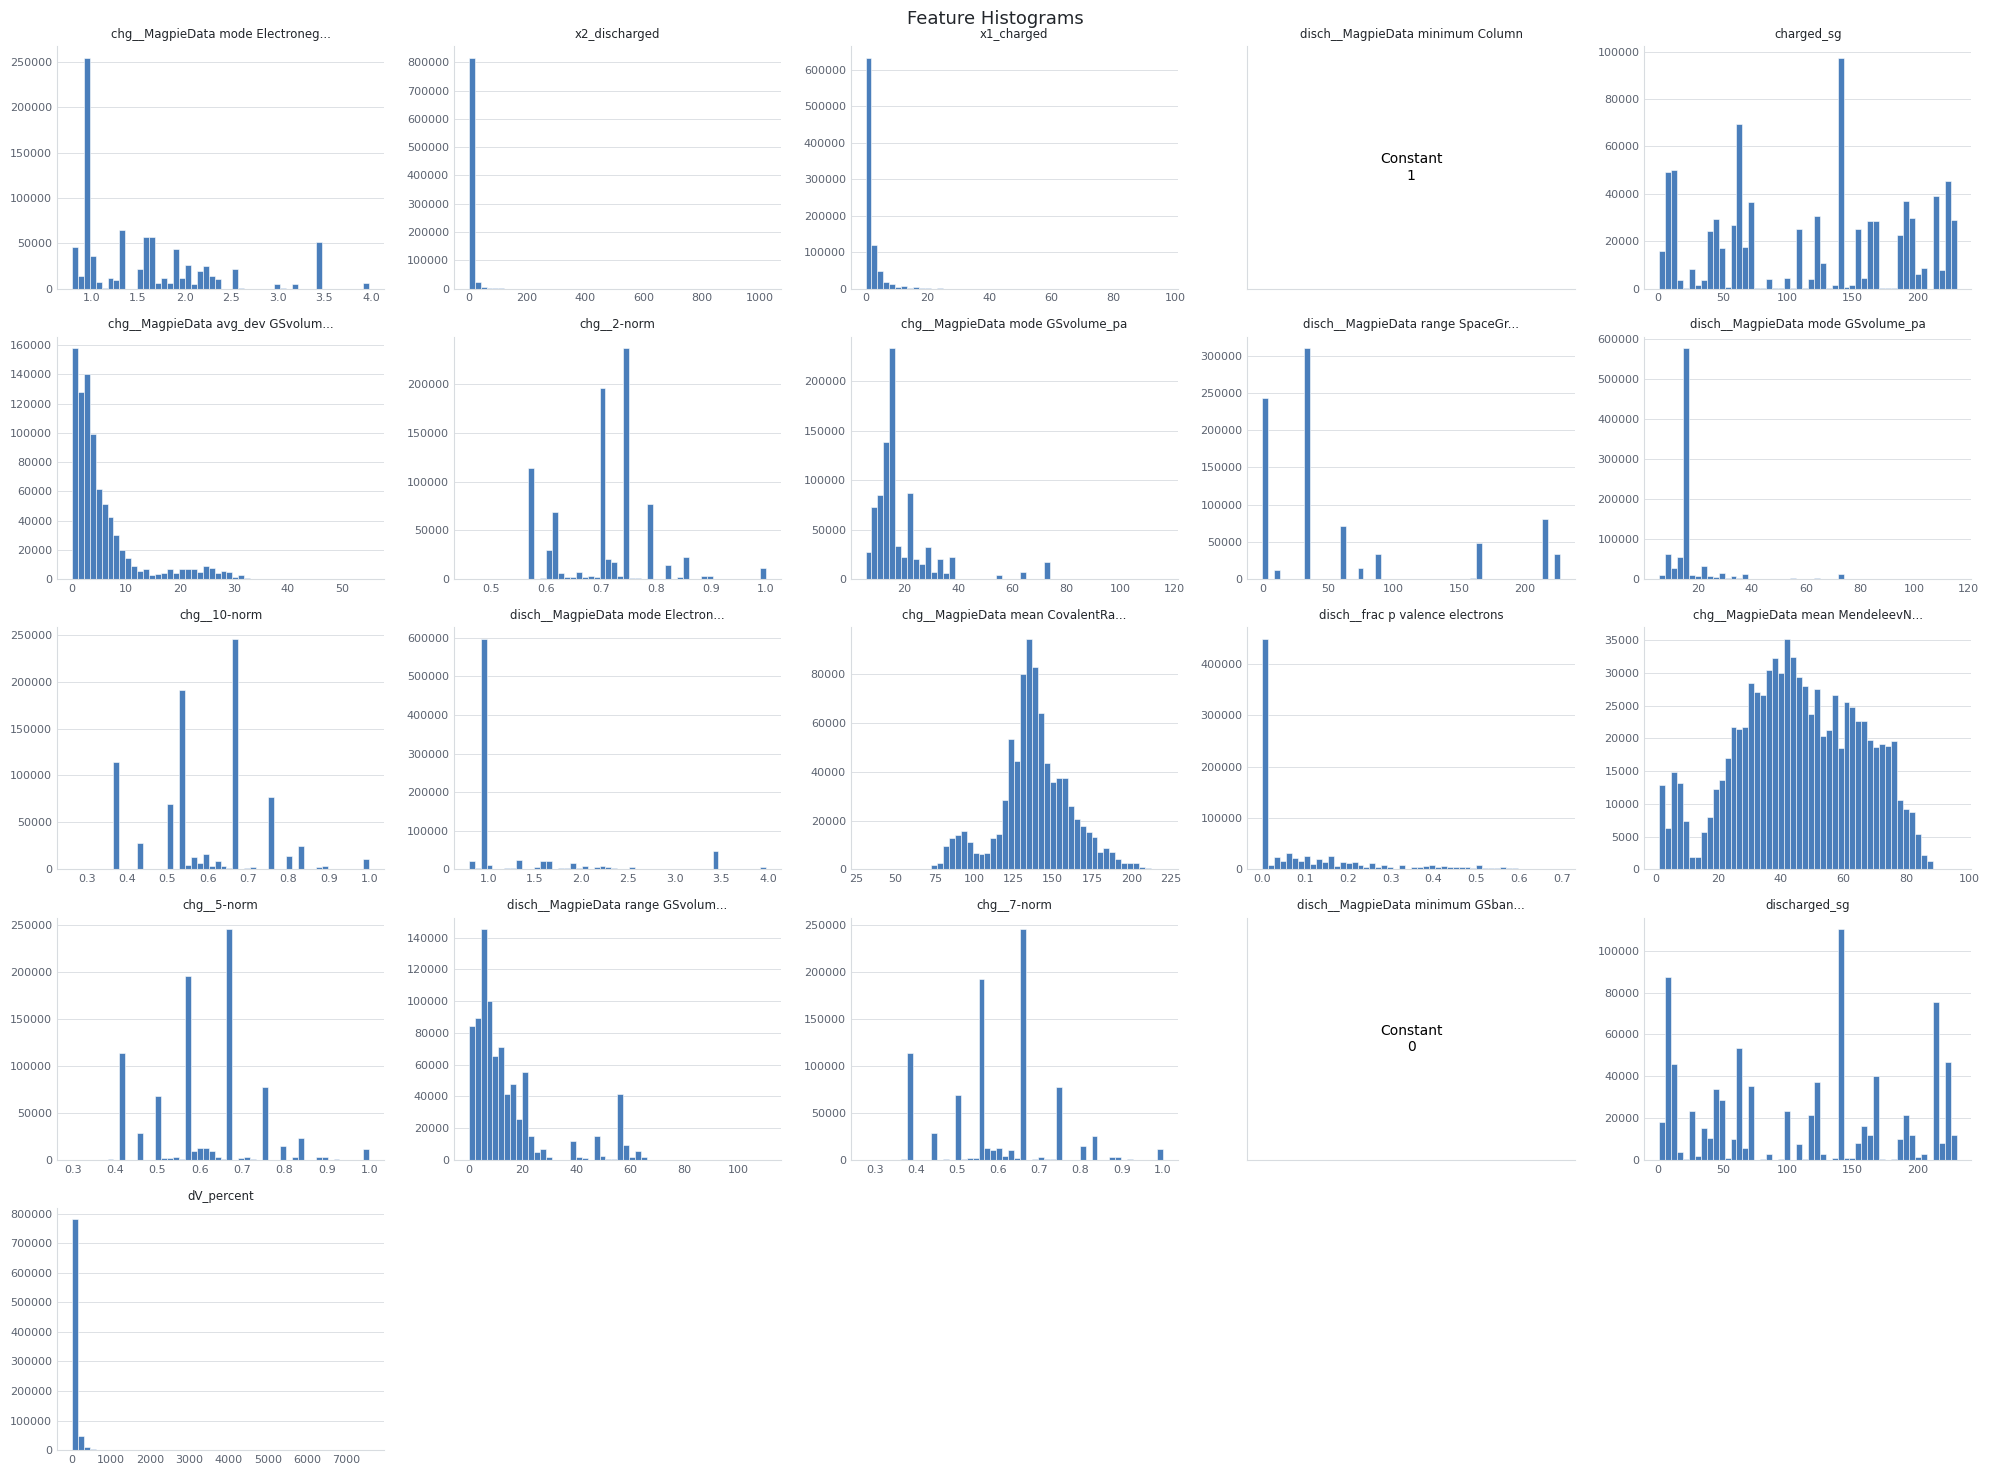

In [10]:
feature_panels(df_dv, draw_histogram, "Feature Histograms")

In [11]:
n_before = len(df_dv)
df_dv = df_dv[df_dv[TARGET] <= DV_MAX].reset_index(drop=True)

print(f"{TARGET} cut-off : <= {DV_MAX} %")
print(f"rows dropped         : {n_before - len(df_dv):,} "
      f"({(n_before - len(df_dv)) / n_before:.2%})")
print(f"rows remaining       : {len(df_dv):,}")
print(f"{TARGET} range now : {df_dv[TARGET].min():.3f} .. {df_dv[TARGET].max():.3f}")

dV_percent cut-off : <= 500 %
rows dropped         : 4,968 (0.59%)
rows remaining       : 843,176
dV_percent range now : 0.000 .. 499.997


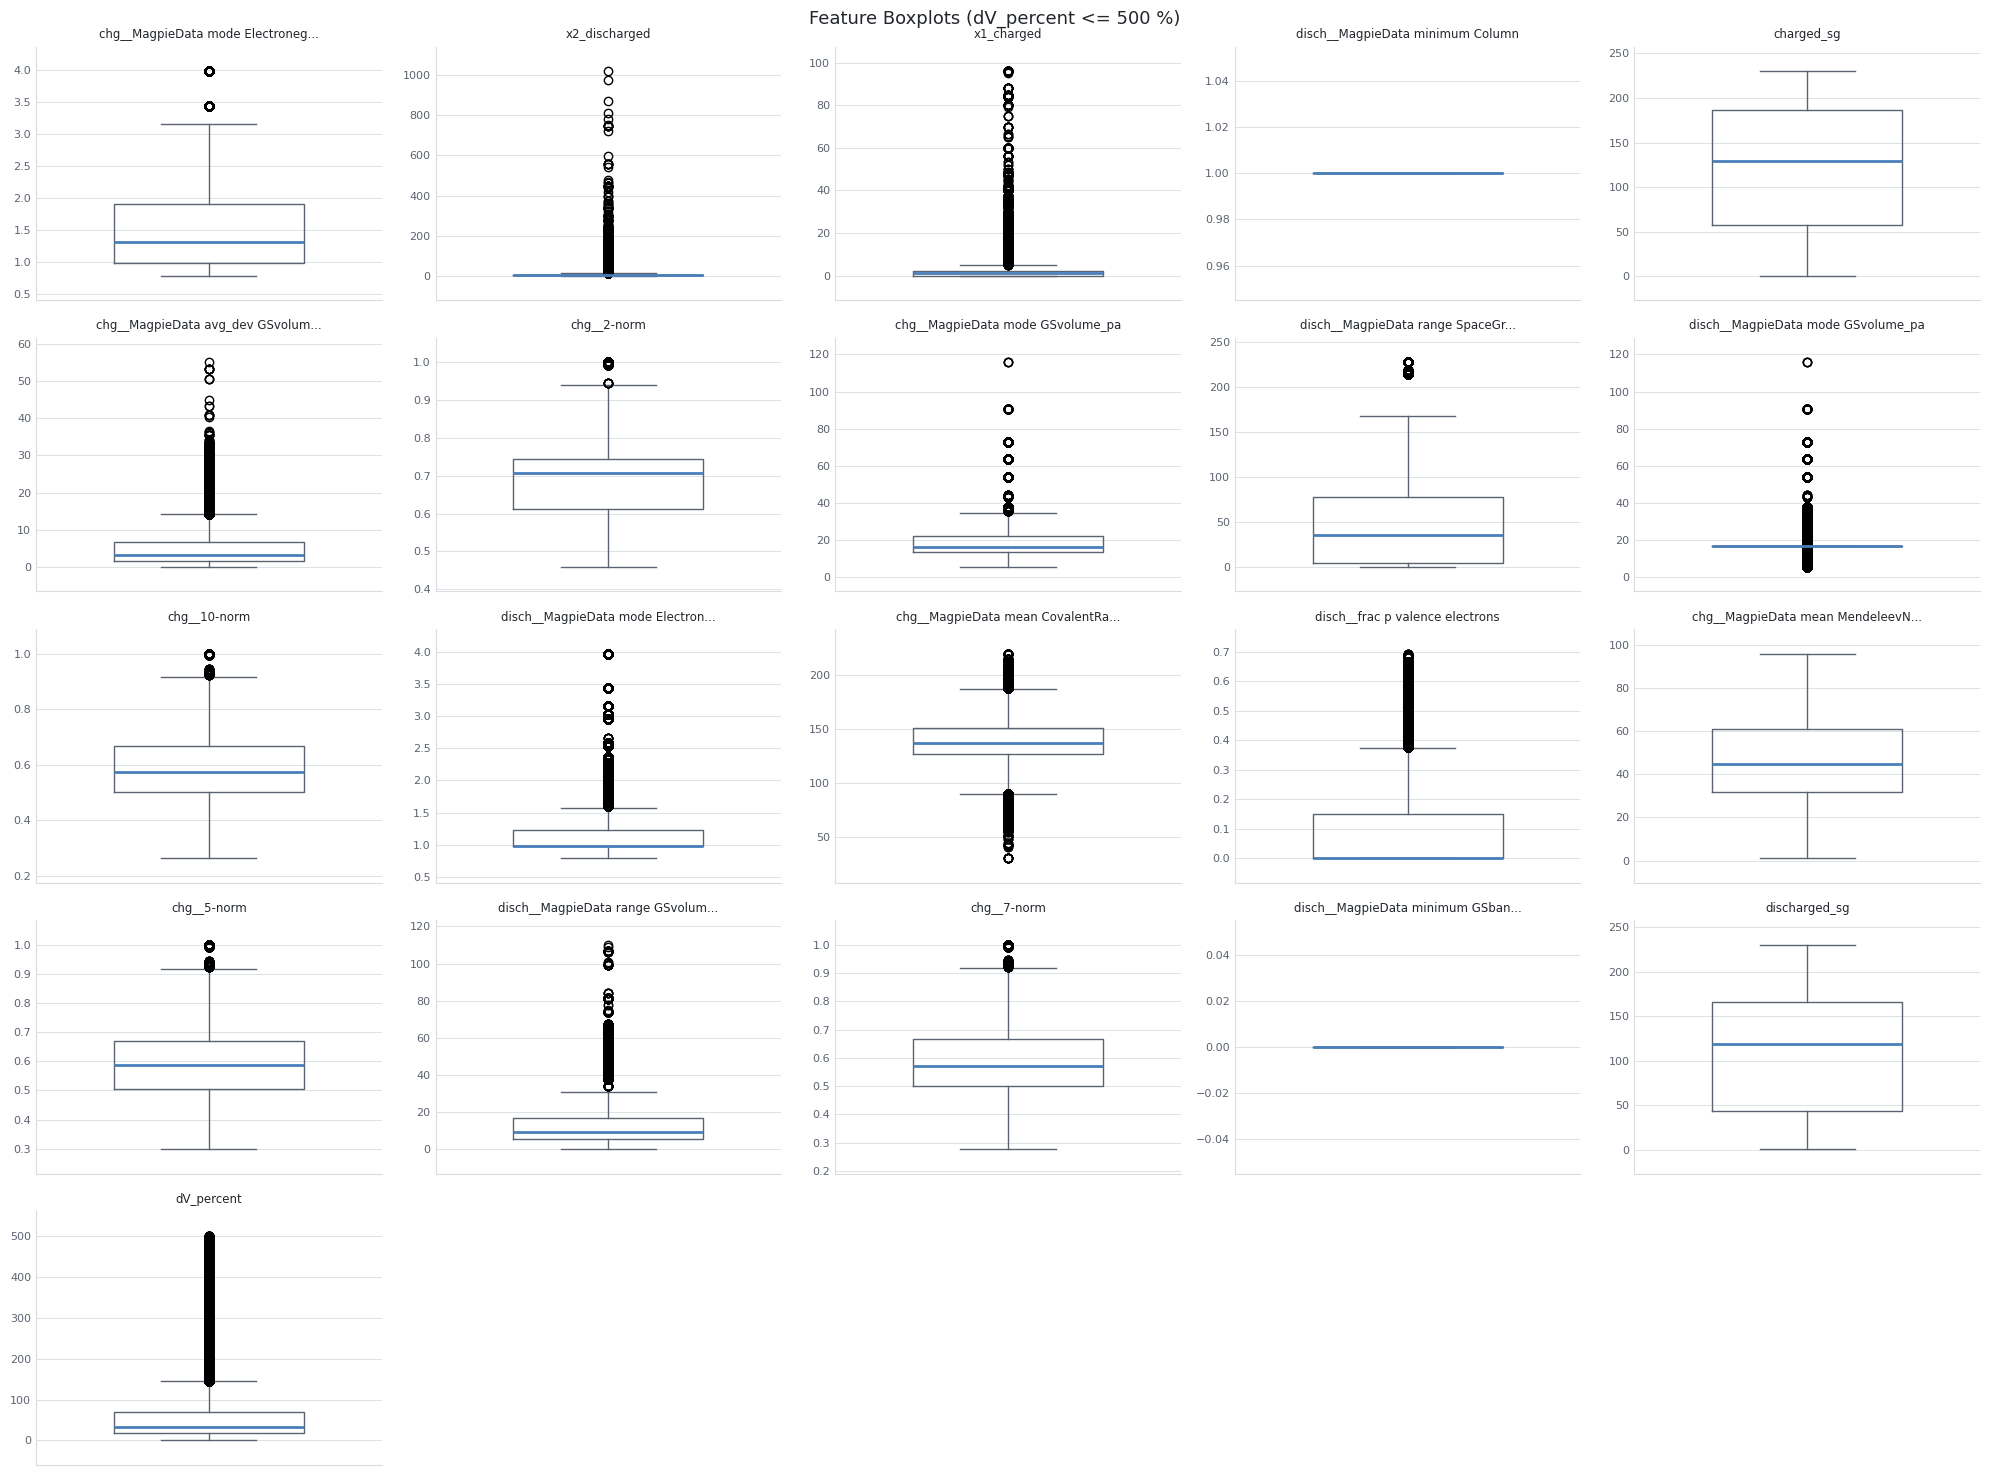

In [12]:
feature_panels(df_dv, draw_boxplot, f"Feature Boxplots ({TARGET} <= {DV_MAX} %)")

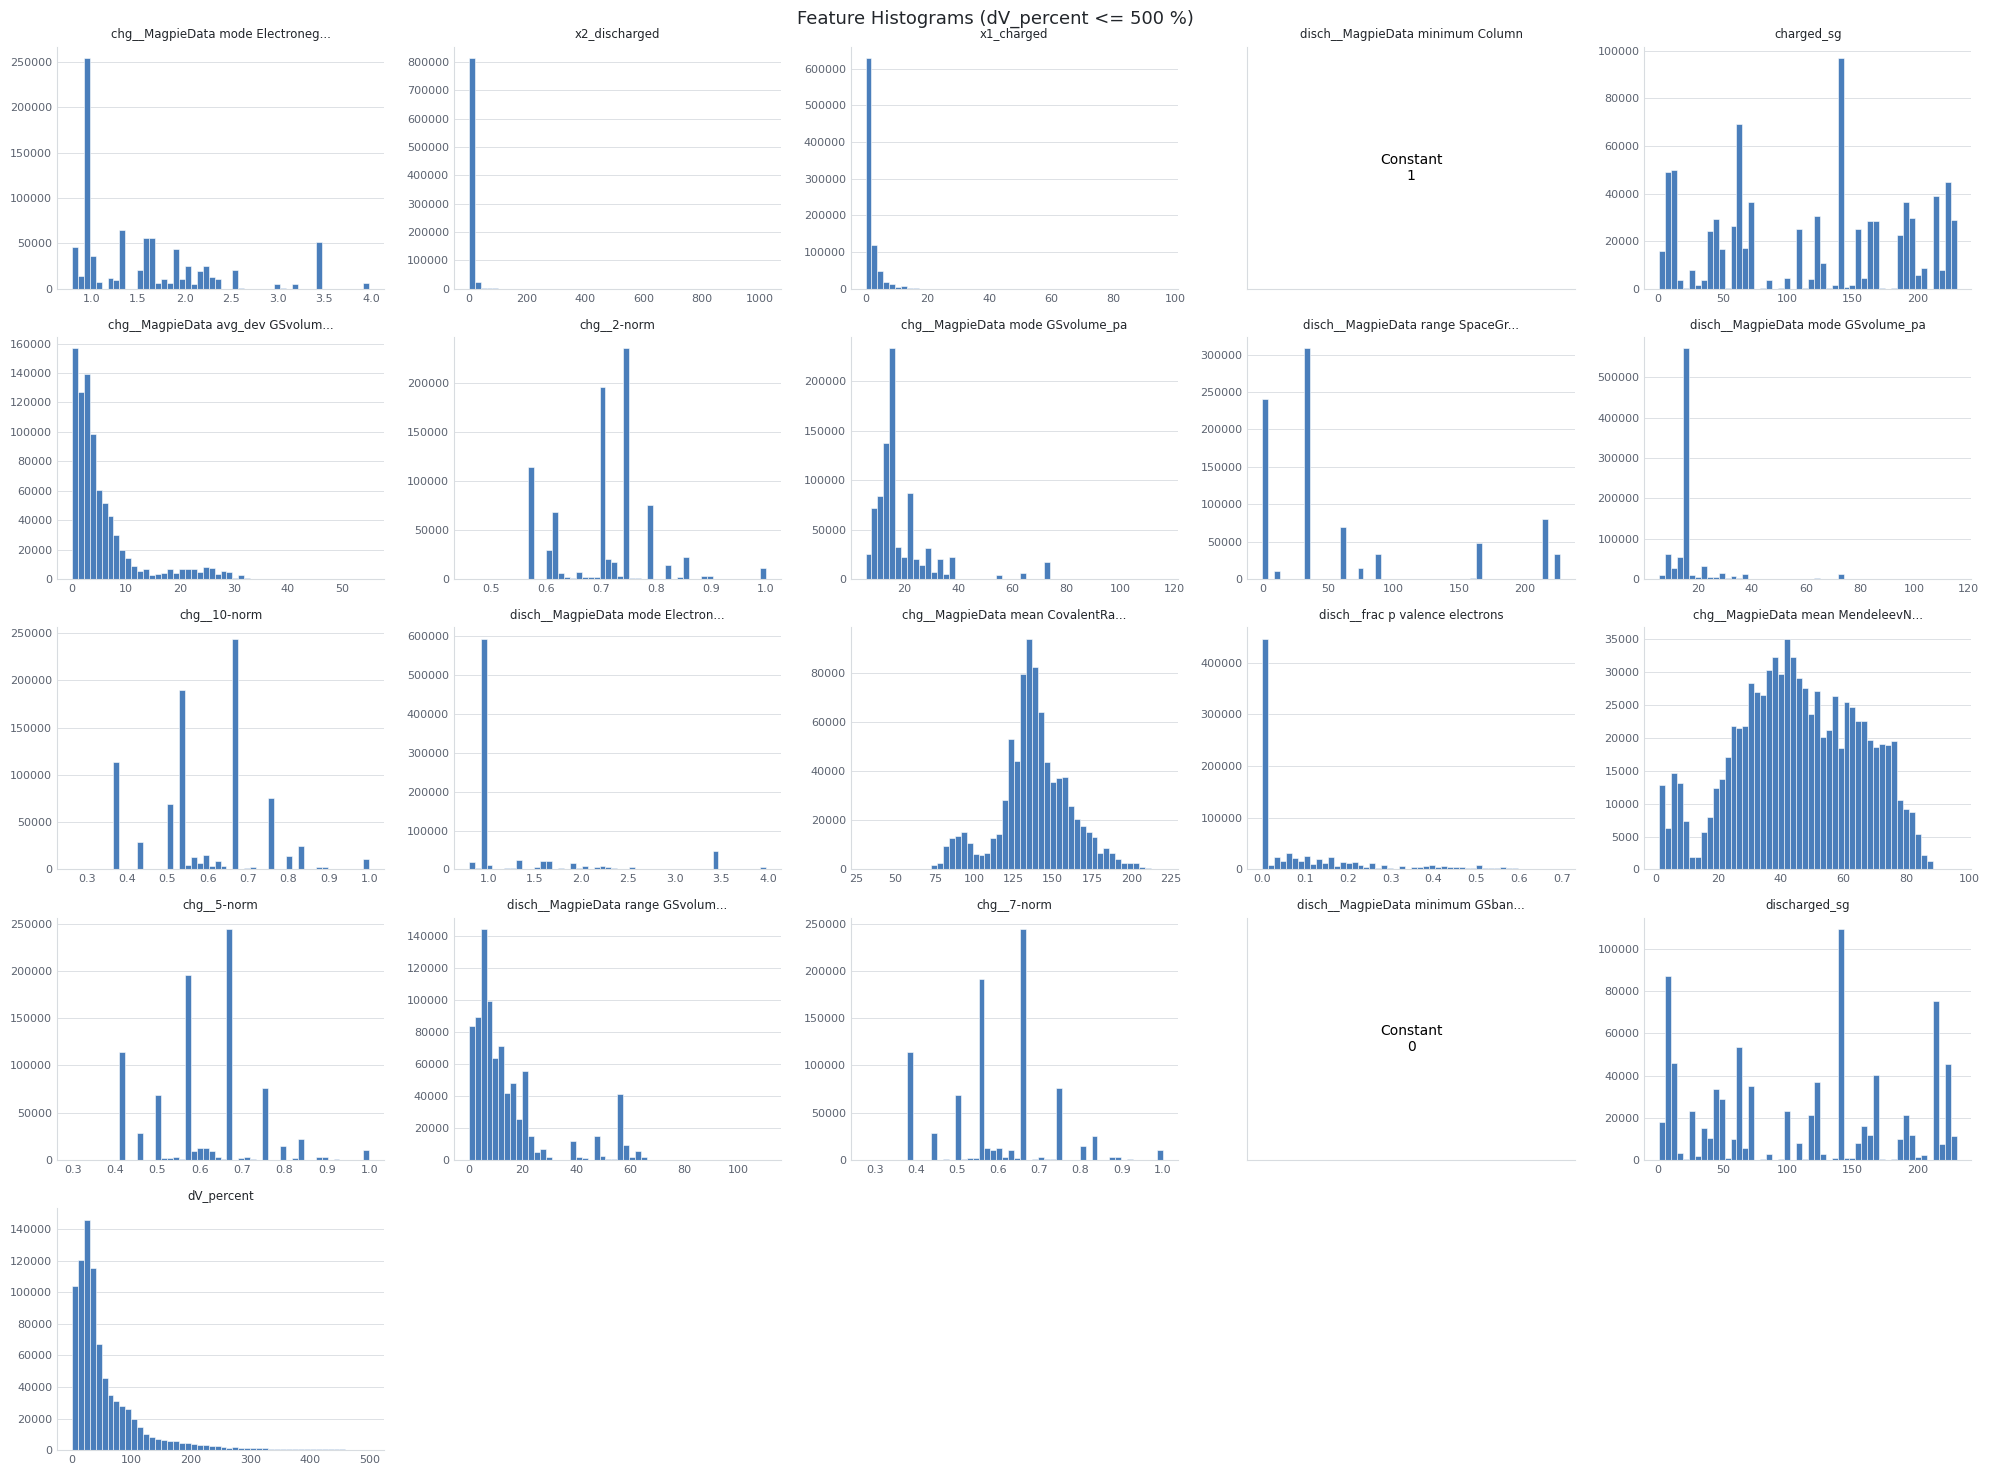

In [13]:
feature_panels(df_dv, draw_histogram, f"Feature Histograms ({TARGET} <= {DV_MAX} %)")

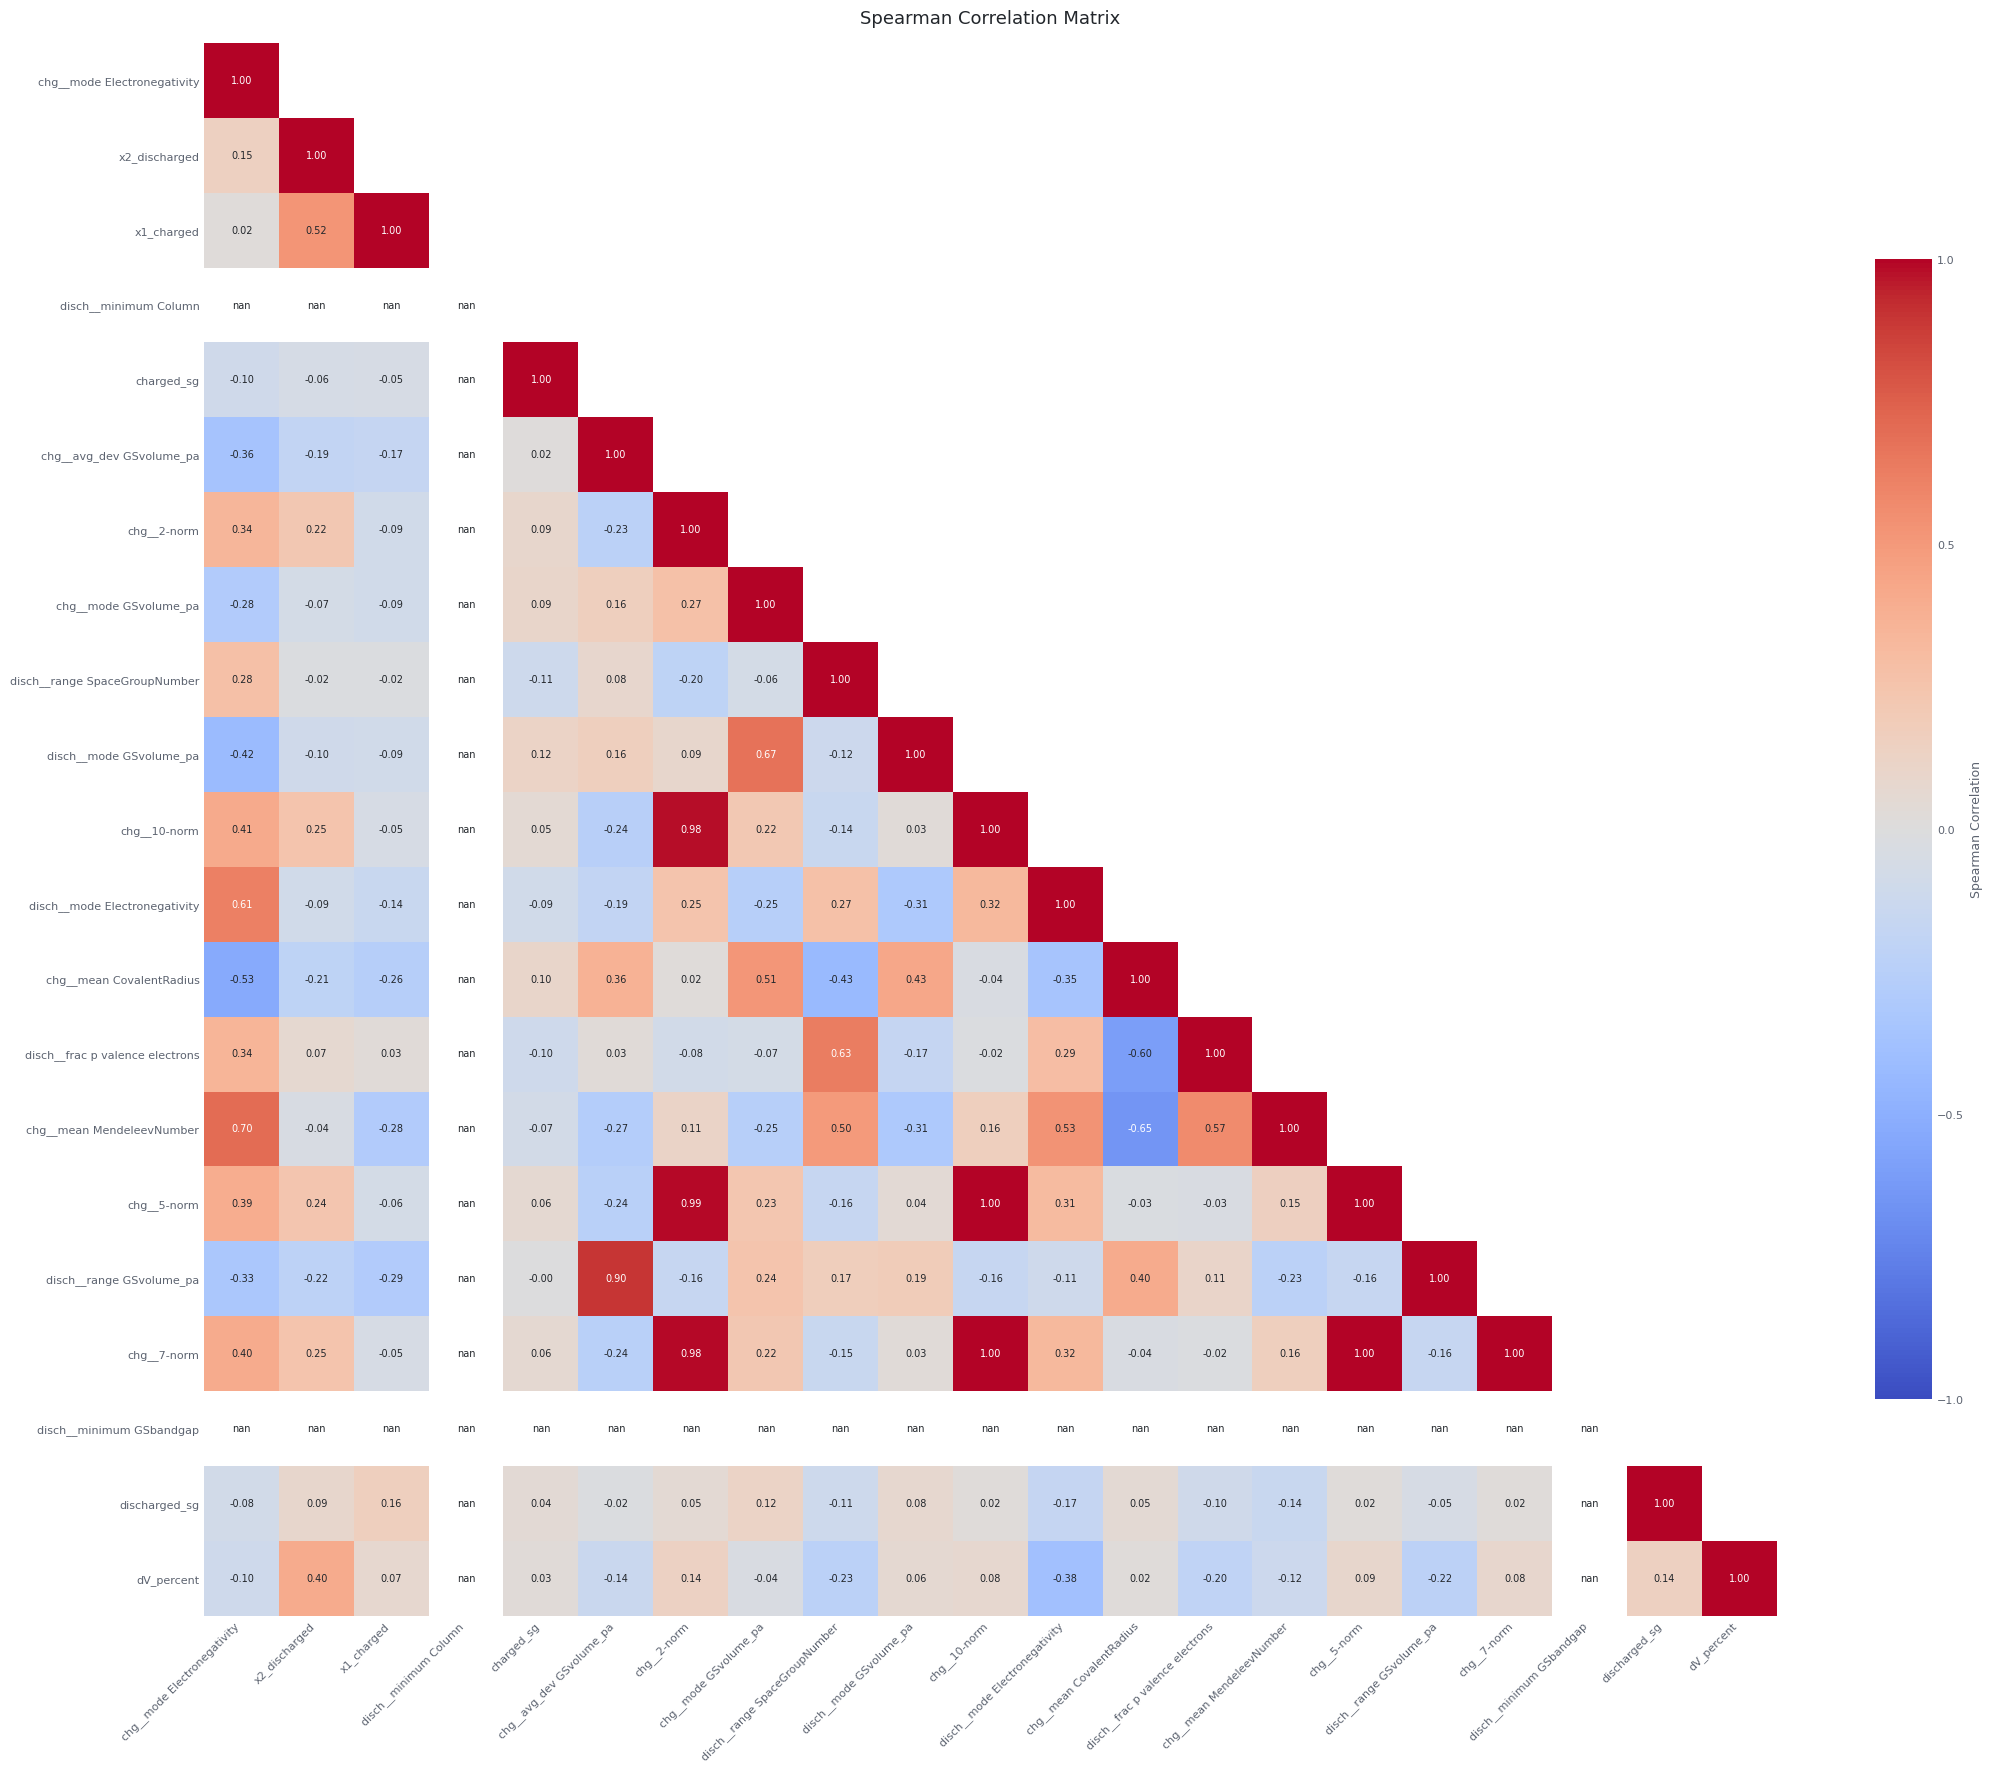

Correlation with 'dV_percent':
  +0.400  x2_discharged
  -0.377  disch__MagpieData mode Electronegativity
  -0.230  disch__MagpieData range SpaceGroupNumber
  -0.220  disch__MagpieData range GSvolume_pa
  -0.200  disch__frac p valence electrons
  +0.145  discharged_sg
  -0.139  chg__MagpieData avg_dev GSvolume_pa
  +0.136  chg__2-norm
  -0.118  chg__MagpieData mean MendeleevNumber
  -0.104  chg__MagpieData mode Electronegativity
  +0.090  chg__5-norm
  +0.079  chg__7-norm
  +0.075  chg__10-norm
  +0.074  x1_charged
  +0.060  disch__MagpieData mode GSvolume_pa
  -0.036  chg__MagpieData mode GSvolume_pa
  +0.028  charged_sg
  +0.018  chg__MagpieData mean CovalentRadius
  +nan  disch__MagpieData minimum Column
  +nan  disch__MagpieData minimum GSbandgap

Feature pairs with |correlation| > 0.8:
  0.999  chg__10-norm <-> chg__7-norm
  0.998  chg__5-norm <-> chg__7-norm
  0.997  chg__10-norm <-> chg__5-norm
  0.988  chg__2-norm <-> chg__5-norm
  0.985  chg__2-norm <-> chg__7-norm
  0.984  ch

(x2_discharged                               0.399667
 disch__MagpieData mode Electronegativity   -0.376792
 disch__MagpieData range SpaceGroupNumber   -0.229863
 disch__MagpieData range GSvolume_pa        -0.220117
 disch__frac p valence electrons            -0.199951
 discharged_sg                               0.144929
 chg__MagpieData avg_dev GSvolume_pa        -0.139465
 chg__2-norm                                 0.135522
 chg__MagpieData mean MendeleevNumber       -0.118460
 chg__MagpieData mode Electronegativity     -0.104206
 chg__5-norm                                 0.089744
 chg__7-norm                                 0.078594
 chg__10-norm                                0.075062
 x1_charged                                  0.073582
 disch__MagpieData mode GSvolume_pa          0.059994
 chg__MagpieData mode GSvolume_pa           -0.035929
 charged_sg                                  0.027710
 chg__MagpieData mean CovalentRadius         0.017685
 disch__MagpieData minimum C

In [14]:
corr = plot_correlation(df_dv)

summarize_correlation(corr, target=TARGET, threshold=0.8)


In [15]:
constant = [c for c in df_dv.columns
            if c != TARGET and df_dv[c].nunique(dropna=False) <= 1]

for c in constant:
    print(f"drop '{c}' (single value: {df_dv[c].iloc[0]})")
df_dv = df_dv.drop(columns=constant)

print(f"\nfeatures remaining : {df_dv.shape[1] - 1} (+ target '{TARGET}')")
print(f"df_dv shape        : {df_dv.shape}")

drop 'disch__MagpieData minimum Column' (single value: 1.0)
drop 'disch__MagpieData minimum GSbandgap' (single value: 0.0)

features remaining : 18 (+ target 'dV_percent')
df_dv shape        : (843176, 19)


In [16]:
# In the Li dataset some chg__ and disch__ columns are identical, because the
# statistic does not depend on the Li content. Keep one and rename it framework__.
features = [c for c in df_dv.columns if c != TARGET]

keep, twins = [], {}
for c in features:
    twin = next((k for k in keep if df_dv[c].equals(df_dv[k])), None)
    if twin is None:
        keep.append(c)
    else:
        twins[c] = twin

if not twins:
    print("no duplicate features.")
else:
    for dropped, kept in twins.items():
        print(f"drop '{dropped}'\n   (identical to '{kept}')")
    df_dv = df_dv.drop(columns=list(twins))

    rename = {kept: kept.replace("chg__", "framework__", 1)
              for dropped, kept in twins.items()
              if kept.startswith("chg__") and dropped.startswith("disch__")}
    if rename:
        df_dv = df_dv.rename(columns=rename)
        print()
        for old, new in rename.items():
            print(f"rename '{old}'\n    -> '{new}'")

print(f"\nfeatures remaining : {df_dv.shape[1] - 1} (+ target '{TARGET}')")
print(f"df_dv shape        : {df_dv.shape}")

no duplicate features.

features remaining : 18 (+ target 'dV_percent')
df_dv shape        : (843176, 19)


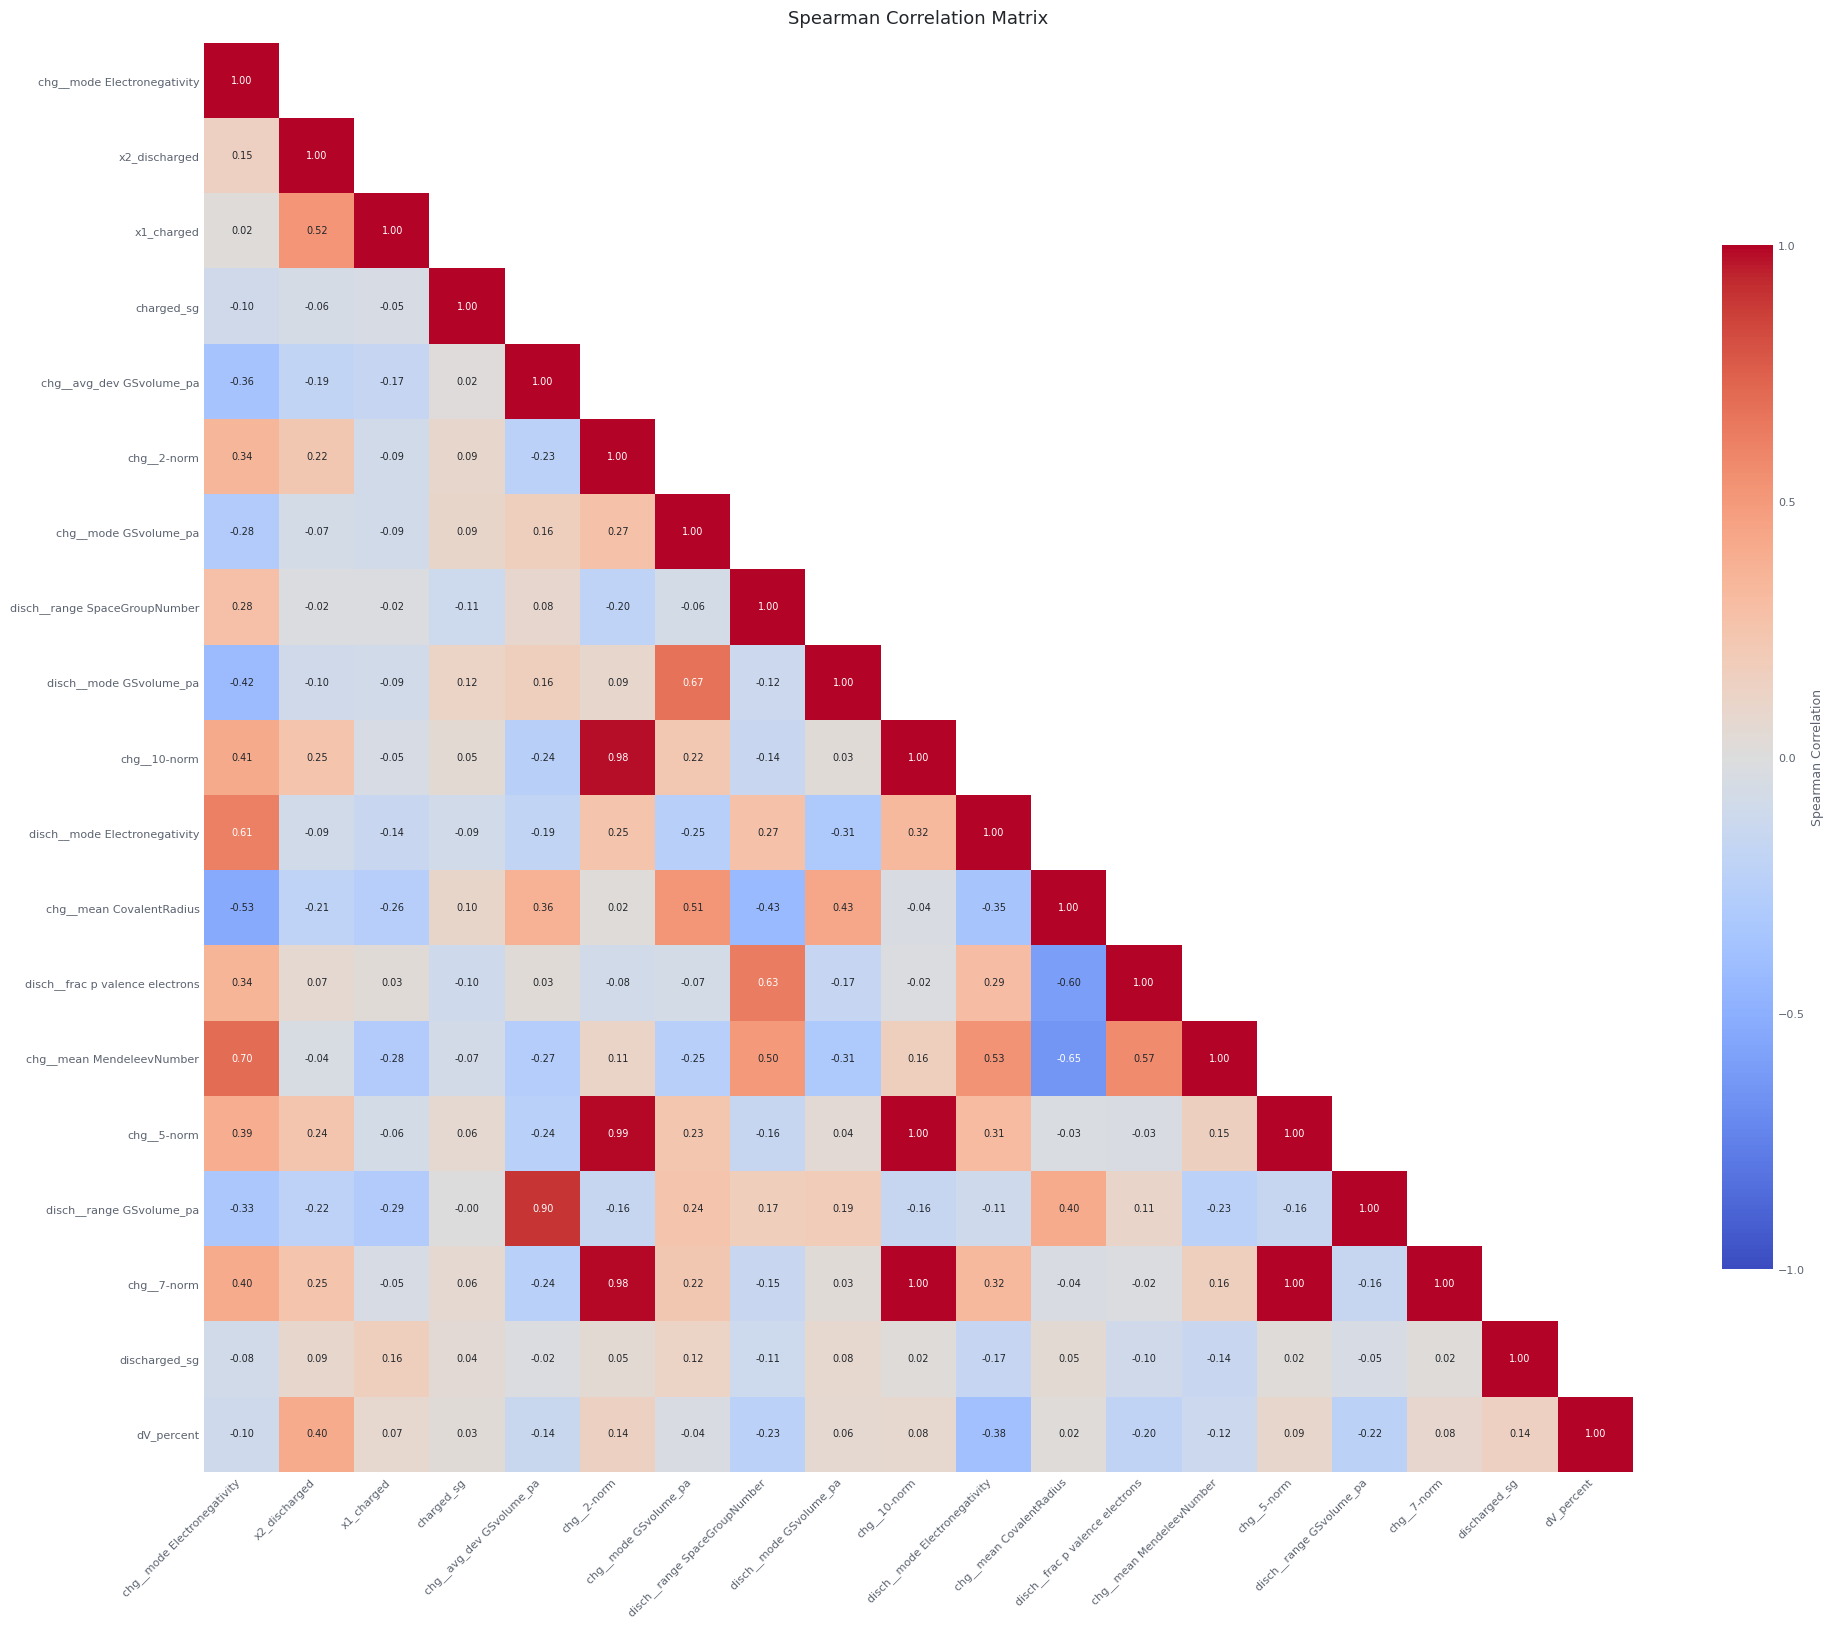

Correlation with 'dV_percent':
  +0.400  x2_discharged
  -0.377  disch__MagpieData mode Electronegativity
  -0.230  disch__MagpieData range SpaceGroupNumber
  -0.220  disch__MagpieData range GSvolume_pa
  -0.200  disch__frac p valence electrons
  +0.145  discharged_sg
  -0.139  chg__MagpieData avg_dev GSvolume_pa
  +0.136  chg__2-norm
  -0.118  chg__MagpieData mean MendeleevNumber
  -0.104  chg__MagpieData mode Electronegativity
  +0.090  chg__5-norm
  +0.079  chg__7-norm
  +0.075  chg__10-norm
  +0.074  x1_charged
  +0.060  disch__MagpieData mode GSvolume_pa
  -0.036  chg__MagpieData mode GSvolume_pa
  +0.028  charged_sg
  +0.018  chg__MagpieData mean CovalentRadius

Feature pairs with |correlation| > 0.8:
  0.999  chg__10-norm <-> chg__7-norm
  0.998  chg__5-norm <-> chg__7-norm
  0.997  chg__10-norm <-> chg__5-norm
  0.988  chg__2-norm <-> chg__5-norm
  0.985  chg__2-norm <-> chg__7-norm
  0.984  chg__2-norm <-> chg__10-norm
  0.896  chg__MagpieData avg_dev GSvolume_pa <-> disch__Ma

(x2_discharged                               0.399667
 disch__MagpieData mode Electronegativity   -0.376792
 disch__MagpieData range SpaceGroupNumber   -0.229863
 disch__MagpieData range GSvolume_pa        -0.220117
 disch__frac p valence electrons            -0.199951
 discharged_sg                               0.144929
 chg__MagpieData avg_dev GSvolume_pa        -0.139465
 chg__2-norm                                 0.135522
 chg__MagpieData mean MendeleevNumber       -0.118460
 chg__MagpieData mode Electronegativity     -0.104206
 chg__5-norm                                 0.089744
 chg__7-norm                                 0.078594
 chg__10-norm                                0.075062
 x1_charged                                  0.073582
 disch__MagpieData mode GSvolume_pa          0.059994
 chg__MagpieData mode GSvolume_pa           -0.035929
 charged_sg                                  0.027710
 chg__MagpieData mean CovalentRadius         0.017685
 Name: dV_percent, dtype: fl

In [17]:
corr = plot_correlation(df_dv)

summarize_correlation(corr, target=TARGET, threshold=0.8)


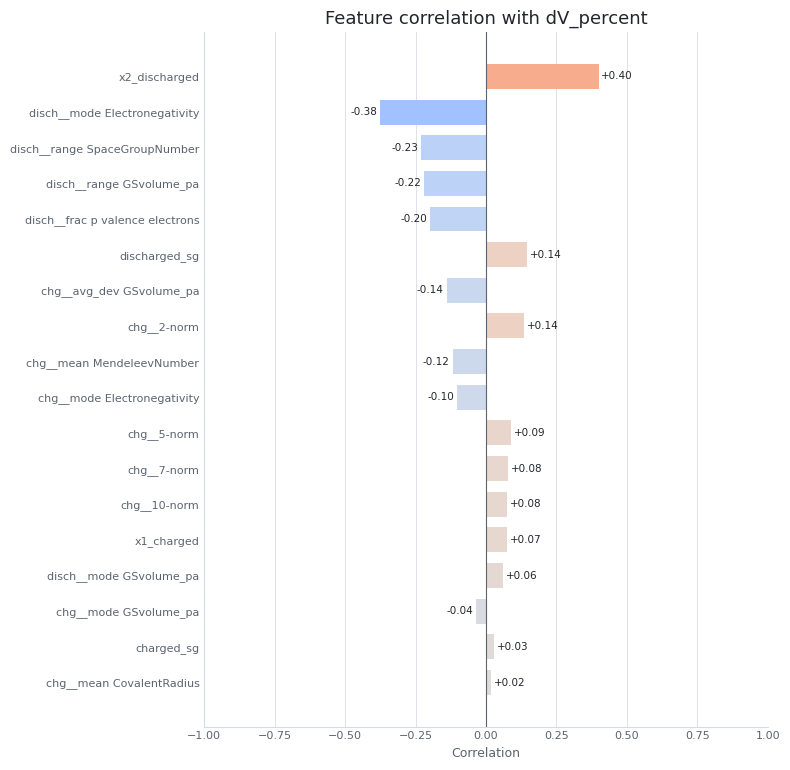

In [18]:
plot_target_correlation(corr, target=TARGET)

# Preprocessing

In [19]:
sg_cols = [c for c in ("charged_sg", "discharged_sg") if c in df_dv.columns]
if SG_AS_CATEGORY and sg_cols:
    df_dv[sg_cols] = df_dv[sg_cols].astype(str)
    print(f"cast to category : {sg_cols}")
else:
    print("space group columns kept numeric")

space group columns kept numeric


In [20]:
X = df_dv.drop(columns=[TARGET])
y = df_dv[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE,
)

categorical = ", ".join(X.select_dtypes(exclude="number").columns) or "none"
print(f"features : {X.shape[1]} (categorical: {categorical})")
print(f"train    : {len(X_train):,} rows")
print(f"test     : {len(X_test):,} rows")

features : 18 (categorical: none)
train    : 674,540 rows
test     : 168,636 rows


In [21]:
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = X_train.select_dtypes(include="number").columns.tolist()

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), cat_cols),
    ("num", "passthrough", num_cols),
])

In [22]:
feature_names = [
    name.split("__", 1)[-1] for name in preprocess.fit(X_train).get_feature_names_out()
]

X_train_enc = pd.DataFrame(preprocess.transform(X_train),
                           columns=feature_names, index=X_train.index)
X_test_enc = pd.DataFrame(preprocess.transform(X_test),
                          columns=feature_names, index=X_test.index)

onehot_cols = [c for c in feature_names if c.startswith(tuple(cat_cols))]
print(f"encoded shape : {X_train_enc.shape[1]} columns "
      f"({len(num_cols)} numeric + {len(onehot_cols)} one-hot)")
X_train_enc.head()

encoded shape : 18 columns (18 numeric + 0 one-hot)


,chg__MagpieData mode Electronegativity,x2_discharged,x1_charged,charged_sg,chg__MagpieData avg_dev GSvolume_pa,chg__2-norm,chg__MagpieData mode GSvolume_pa,disch__MagpieData range SpaceGroupNumber,disch__MagpieData mode GSvolume_pa,chg__10-norm,disch__MagpieData mode Electronegativity,chg__MagpieData mean CovalentRadius,disch__frac p valence electrons,chg__MagpieData mean MendeleevNumber,chg__5-norm,disch__MagpieData range GSvolume_pa,chg__7-norm,discharged_sg
630704,1.90,18.0,2.0,223.0,0.865625,0.790569,14.285000,35.0,16.593333,0.750001,0.98,142.250000,0.000000,40.000000,0.750616,2.308333,0.750049,187.0
9081,3.44,10.0,4.0,9.0,1.753197,0.654654,9.105000,217.0,9.105000,0.571484,3.44,93.714286,0.376471,65.571429,0.575065,7.488333,0.572069,9.0
451915,0.98,7.0,1.0,187.0,2.803333,0.707107,16.593333,35.0,16.593333,0.535887,0.98,151.500000,0.000000,23.000000,0.574349,5.606667,0.552045,225.0
490594,1.78,2.0,0.0,63.0,0.608889,0.745356,24.260000,90.0,24.260000,0.666732,1.78,141.666667,0.068966,72.666667,0.670782,7.666667,0.667408,139.0
96812,1.61,2.0,0.0,229.0,0.000000,1.000000,16.480000,4.0,16.480000,1.000000,1.61,121.000000,0.272727,73.000000,1.000000,0.113333,1.000000,164.0


# Model Training

In [23]:
# LightGBM uses OpenCL ("gpu"); this build has no CUDA learner
models = {
    "XGBoost (boosting)": XGBRegressor(
        objective="reg:squarederror", tree_method="hist", device="cuda",
        random_state=RANDOM_STATE,
    ),
    "LightGBM (boosting)": LGBMRegressor(
        n_estimators=100, device="gpu", random_state=RANDOM_STATE, verbose=-1,
    ),
    "CatBoost (boosting)": CatBoostRegressor(
        iterations=100, task_type="GPU", devices="0", random_state=RANDOM_STATE,
        verbose=0,
    ),
    "RandomForest (cuML GPU)": cuRF(
        n_estimators=100, max_depth=16, n_streams=4, random_state=RANDOM_STATE,
    ),
}

for name, model in models.items():
    print(f"{name:<24} {type(model).__name__}")

XGBoost (boosting)       XGBRegressor
LightGBM (boosting)      LGBMRegressor
CatBoost (boosting)      CatBoostRegressor
RandomForest (cuML GPU)  RandomForestRegressor


In [24]:
baseline_scores, baseline_preds = evaluate_all(
    models, X_train_enc, y_train, X_test_enc, y_test, heading="Baseline (default params)",
)

/home/reesarosyid/Documents/Battery/.venv/lib/python3.12/site-packages/xgboost/core.py:553: UserWarning: [16:52:36] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


XGBoost (boosting)       CV MAE=11.8955+/-0.1077  CV RMSE=20.2318  CV R2=0.9049  |  test MAE=11.7409  (4s)
LightGBM (boosting)      CV MAE=13.9794+/-0.0926  CV RMSE=23.2471  CV R2=0.8745  |  test MAE=13.9120  (6s)
CatBoost (boosting)      CV MAE=14.0473+/-0.0882  CV RMSE=23.7044  CV R2=0.8695  |  test MAE=13.9957  (9s)


[16:53:05] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.0
[16:53:15] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.0
[16:53:22] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4

RandomForest (cuML GPU)  CV MAE=10.5315+/-0.0762  CV RMSE=19.3432  CV R2=0.9131  |  test MAE=10.4546  (63s)

Baseline (default params), 10-fold CV (sorted by CV MAE)
                         CV RMSE  CV RMSE std   CV MAE  CV MAE std   CV R2  CV R2 std  test RMSE  test MAE  test R2   CV (s)  refit (s)
model                                                                                                                                  
RandomForest (cuML GPU)  19.3432       0.3014  10.5315      0.0762  0.9131     0.0025    18.8856   10.4546   0.9173  62.6471     6.6776
XGBoost (boosting)       20.2318       0.3056  11.8955      0.1077  0.9049     0.0034    19.7836   11.7409   0.9093   3.9911     0.2766
LightGBM (boosting)      23.2471       0.3105  13.9794      0.0926  0.8745     0.0030    23.0383   13.9120   0.8770   6.1733     0.5855
CatBoost (boosting)      23.7044       0.2651  14.0473      0.0882  0.8695     0.0029    23.3345   13.9957   0.8738   8.7595     0.5637


[16:54:19] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.0


In [25]:
# Random forest is much slower than boosting, so it is tuned on a subsample
# and re-scored on the full training set afterwards.
rf_rng = np.random.RandomState(RANDOM_STATE)
rf_idx = rf_rng.choice(len(X_train_enc), size=min(RF_TUNE_SAMPLE, len(X_train_enc)),
                       replace=False)
X_rf, y_rf = X_train_enc.iloc[rf_idx], y_train.iloc[rf_idx]

# name -> (estimator, param grid, X, y)
grids = {
    "XGBoost (boosting)": (
        XGBRegressor(objective="reg:squarederror", tree_method="hist",
                     device="cuda", random_state=RANDOM_STATE),
        {"n_estimators": [400, 800],
         "max_depth": [6, 10],
         "learning_rate": [0.05, 0.1]},
        X_train_enc, y_train),
    "LightGBM (boosting)": (
        LGBMRegressor(device="gpu", random_state=RANDOM_STATE, verbose=-1),
        {"n_estimators": [400, 800],
         "num_leaves": [31, 63],
         "learning_rate": [0.05, 0.1]},
        X_train_enc, y_train),
    "CatBoost (boosting)": (
        CatBoostRegressor(task_type="GPU", devices="0", random_state=RANDOM_STATE,
                          verbose=0),
        {"iterations": [400, 800],
         "depth": [6, 10],
         "learning_rate": [0.05, 0.1]},
        X_train_enc, y_train),
    "RandomForest (cuML GPU)": (
        cuRF(n_streams=4, random_state=RANDOM_STATE),
        {"n_estimators": [100, 200],
         "max_depth": [12, 16]},
        X_rf, y_rf),
}

best_params, tune_rows = {}, []
for name, (model, grid, X_tune, y_tune) in grids.items():
    search = GridSearchCV(model, grid, scoring="neg_mean_absolute_error",
                          cv=kf, n_jobs=1, refit=False, error_score="raise")
    start = time.perf_counter()
    search.fit(X_tune, y_tune)
    elapsed = time.perf_counter() - start

    best_params[name] = search.best_params_
    tune_rows.append({
        "model": name,
        "search CV MAE": -search.best_score_,
        "combos": len(search.cv_results_["params"]),
        "fits": len(search.cv_results_["params"]) * K,
        "tune (s)": elapsed,
    })
    print(f"{name:<24} search CV MAE={-search.best_score_:.4f}  ({elapsed:.0f}s)  "
          f"best={search.best_params_}")

tuning_summary = pd.DataFrame(tune_rows).set_index("model").sort_values("search CV MAE")
print(f"\nGridSearchCV summary ({K}-fold)")
print(tuning_summary.round(4).to_string())

XGBoost (boosting)       search CV MAE=5.4564  (210s)  best={'learning_rate': 0.1, 'max_depth': 10, 'n_estimators': 800}
LightGBM (boosting)      search CV MAE=8.2696  (202s)  best={'learning_rate': 0.1, 'n_estimators': 800, 'num_leaves': 63}
CatBoost (boosting)      search CV MAE=9.6916  (200s)  best={'depth': 10, 'iterations': 800, 'learning_rate': 0.1}


[17:04:33] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.0
[17:04:34] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.0
[17:04:35] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4

RandomForest (cuML GPU)  search CV MAE=11.8638  (93s)  best={'max_depth': 16, 'n_estimators': 200}

GridSearchCV summary (10-fold)
                         search CV MAE  combos  fits  tune (s)
model                                                         
XGBoost (boosting)              5.4564       8    80  210.2532
LightGBM (boosting)             8.2696       8    80  201.6975
CatBoost (boosting)             9.6916       8    80  200.2847
RandomForest (cuML GPU)        11.8638       4    40   93.3843


[17:06:04] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.0


# Results

In [26]:
tuned_models = {
    name: clone(grids[name][0]).set_params(**params)
    for name, params in best_params.items()
}

tuned_scores, tuned_preds = evaluate_all(
    tuned_models, X_train_enc, y_train, X_test_enc, y_test,
    heading="Tuned (GridSearchCV best params)",
)

XGBoost (boosting)       CV MAE=5.4564+/-0.0448  CV RMSE=9.8981  CV R2=0.9772  |  test MAE=5.3964  (52s)
LightGBM (boosting)      CV MAE=8.2691+/-0.0615  CV RMSE=13.1303  CV R2=0.9600  |  test MAE=8.2111  (31s)
CatBoost (boosting)      CV MAE=9.6938+/-0.0609  CV RMSE=15.8180  CV R2=0.9419  |  test MAE=9.6147  (44s)


[17:08:44] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.0
[17:08:59] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.0
[17:09:14] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4

RandomForest (cuML GPU)  CV MAE=10.5224+/-0.0827  CV RMSE=19.3282  CV R2=0.9133  |  test MAE=10.4488  (121s)

Tuned (GridSearchCV best params), 10-fold CV (sorted by CV MAE)
                         CV RMSE  CV RMSE std   CV MAE  CV MAE std   CV R2  CV R2 std  test RMSE  test MAE  test R2    CV (s)  refit (s)
model                                                                                                                                   
XGBoost (boosting)        9.8981       0.2664   5.4564      0.0448  0.9772     0.0012     9.3288    5.3964   0.9798   51.6666     5.2879
LightGBM (boosting)      13.1303       0.1541   8.2691      0.0615  0.9600     0.0012    12.7682    8.2111   0.9622   30.6568     3.1474
CatBoost (boosting)      15.8180       0.1766   9.6938      0.0609  0.9419     0.0018    15.4345    9.6147   0.9448   43.5874     4.7630
RandomForest (cuML GPU)  19.3282       0.3119  10.5224      0.0827  0.9133     0.0026    18.8788   10.4488   0.9174  120.5968    13.3247


[17:11:08] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.7.0


10-fold CV and test, before vs after tuning (gain > 0 = improvement)
                         CV MAE (base)  CV MAE (tuned)  CV RMSE (base)  CV RMSE (tuned)  CV R2 (base)  CV R2 (tuned)  test MAE (base)  test MAE (tuned)  test RMSE (base)  test RMSE (tuned)  test R2 (base)  test R2 (tuned)  CV MAE gain  test MAE gain
model                                                                                                                                                                                                                                                    
XGBoost (boosting)             11.8955          5.4564         20.2318           9.8981        0.9049         0.9772          11.7409            5.3964           19.7836             9.3288          0.9093           0.9798       6.4390         6.3445
LightGBM (boosting)            13.9794          8.2691         23.2471          13.1303        0.8745         0.9600          13.9120            8.2111           23.0383            

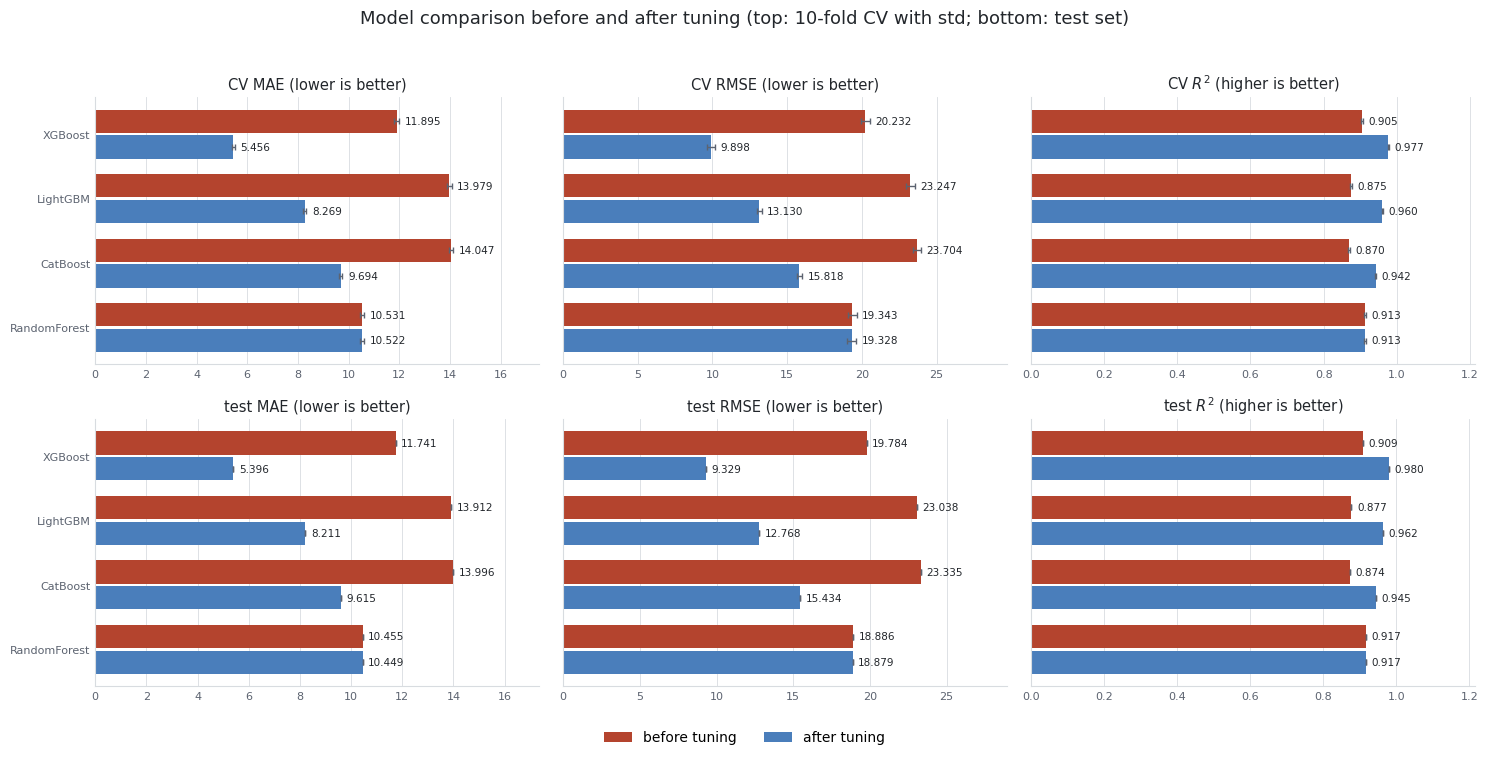

In [27]:
METRICS = ["MAE", "RMSE", "R2"]
BAR_HEIGHT = 0.36
BAR_OFFSET = BAR_HEIGHT / 2 + 0.02

compare = baseline_scores.join(tuned_scores, lsuffix=" (base)", rsuffix=" (tuned)")
compare = compare.loc[compare["CV MAE (tuned)"].sort_values().index]
compare["CV MAE gain"] = compare["CV MAE (base)"] - compare["CV MAE (tuned)"]
compare["test MAE gain"] = compare["test MAE (base)"] - compare["test MAE (tuned)"]

table_cols = [f"{source} {metric} ({stage})"
              for source in ("CV", "test") for metric in METRICS
              for stage in ("base", "tuned")] + ["CV MAE gain", "test MAE gain"]
print(f"{K}-fold CV and test, before vs after tuning (gain > 0 = improvement)")
print(compare[table_cols].round(4).to_string())

positions = np.arange(len(compare))
no_error = np.zeros(len(compare))

fig, axes = plt.subplots(2, len(METRICS), figsize=(15, 7.6), sharey=True)

for axrow, source in zip(axes, ["CV", "test"]):
    for ax, metric in zip(axrow, METRICS):
        series = [
            ("before tuning", BASE_COLOR, -BAR_OFFSET,
             compare[f"{source} {metric} (base)"],
             compare[f"CV {metric} std (base)"] if source == "CV" else no_error),
            ("after tuning", TUNED_COLOR, BAR_OFFSET,
             compare[f"{source} {metric} (tuned)"],
             compare[f"CV {metric} std (tuned)"] if source == "CV" else no_error),
        ]

        for label, color, shift, values, spread in series:
            ax.barh(positions + shift, values, BAR_HEIGHT, xerr=spread, color=color,
                    error_kw={"ecolor": SPINE, "elinewidth": 1, "capsize": 2.5},
                    label=label)
            for y_pos, value, error in zip(positions + shift, values, spread):
                ax.annotate(f"{value:.3f}", (value + error, y_pos),
                            textcoords="offset points", xytext=(4, 0),
                            va="center", fontsize=7.5, color=TEXT)

        direction = "higher is better" if metric == "R2" else "lower is better"
        pretty = "$R^2$" if metric == "R2" else metric
        ax.set_title(f"{source} {pretty} ({direction})", fontsize=10.5, color=TEXT)
        ax.set_yticks(positions)
        ax.set_yticklabels(short_names(compare.index), fontsize=9)
        ax.margins(x=0.24)
        style_axes(ax, grid_axis="x")

# sharey: one flip applies to every panel
axes[0, 0].invert_yaxis()

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False, fontsize=10)
fig.suptitle(f"Model comparison before and after tuning "
             f"(top: {K}-fold CV with std; bottom: test set)",
             fontsize=13, color=TEXT)
fig.tight_layout(rect=(0, 0.05, 1, 0.96))
plt.show()

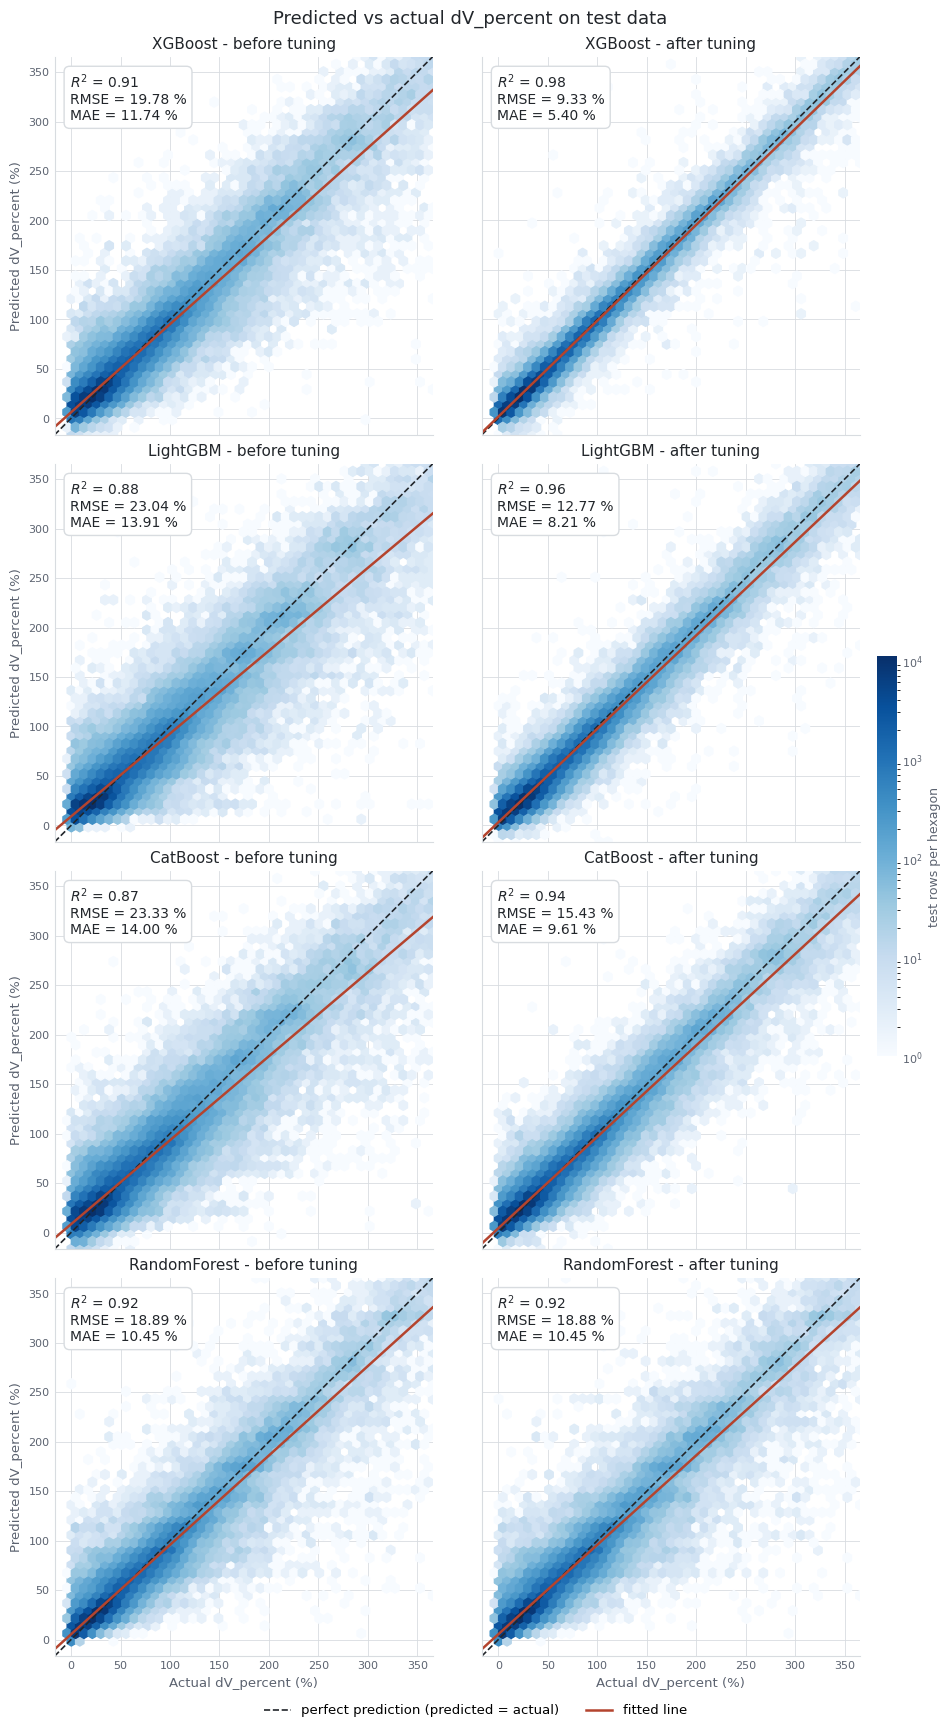

In [28]:
if TRIM_PRED_AXES:
    low, high = trimmed_limits(y_test)
else:
    shown = np.concatenate([y_test, *baseline_preds.values(), *tuned_preds.values()])
    low, high = shown.min(), shown.max()

stages = [("before tuning", baseline_preds), ("after tuning", tuned_preds)]

fig, axes = plt.subplots(len(compare), len(stages), figsize=(9.5, 4.3 * len(compare)),
                         sharex=True, sharey=True, layout="constrained")
axes = np.atleast_2d(axes)

for row, (axrow, name) in enumerate(zip(axes, compare.index)):
    for col, (ax, (stage, preds)) in enumerate(zip(axrow, stages)):
        hexes, line_handles = plot_pred_vs_actual(ax, y_test, preds[name], low, high)

        ax.set_title(f"{short_names([name])[0]} - {stage}", fontsize=11, color=TEXT)
        if row == len(compare) - 1:
            ax.set_xlabel(f"Actual {TARGET} ({UNIT})", fontsize=9.5, color=SPINE)
        if col == 0:
            ax.set_ylabel(f"Predicted {TARGET} ({UNIT})", fontsize=9.5, color=SPINE)

bar = fig.colorbar(hexes, ax=axes, shrink=0.25, pad=0.02)
bar.set_label("test rows per hexagon", color=SPINE, fontsize=9)
bar.ax.tick_params(colors=SPINE, labelsize=8, length=0)
bar.outline.set_visible(False)

fig.legend(handles=list(line_handles), loc="outside lower center", ncol=2,
           frameon=False, fontsize=9.5)
fig.suptitle(f"Predicted vs actual {TARGET} on test data", fontsize=13, color=TEXT)
plt.show()

# SHAP Analysis

In [29]:
# TreeExplainer does not support the cuML forest, so the best boosting model is used
explainable = [name for name in tuned_scores.index if "cuML" not in name]
shap_name = tuned_scores.loc[explainable, "CV MAE"].idxmin()
shap_model = tuned_models[shap_name]

# avoid XGBoost device-mismatch warnings on numpy input
if isinstance(shap_model, XGBRegressor):
    shap_model.set_params(device="cpu")

rng = np.random.RandomState(RANDOM_STATE)
shap_idx = rng.choice(len(X_test_enc), size=min(SHAP_SAMPLE, len(X_test_enc)),
                      replace=False)
X_shap = X_test_enc.iloc[shap_idx]

explainer = shap.TreeExplainer(shap_model)
shap_values = explainer(X_shap)

print(f"model       : {shap_name}  ({type(shap_model).__name__})")
print(f"SHAP values : {shap_values.values.shape[0]:,} rows x "
      f"{shap_values.values.shape[1]} features")

model       : XGBoost (boosting)  (XGBRegressor)
SHAP values : 3,000 rows x 18 features


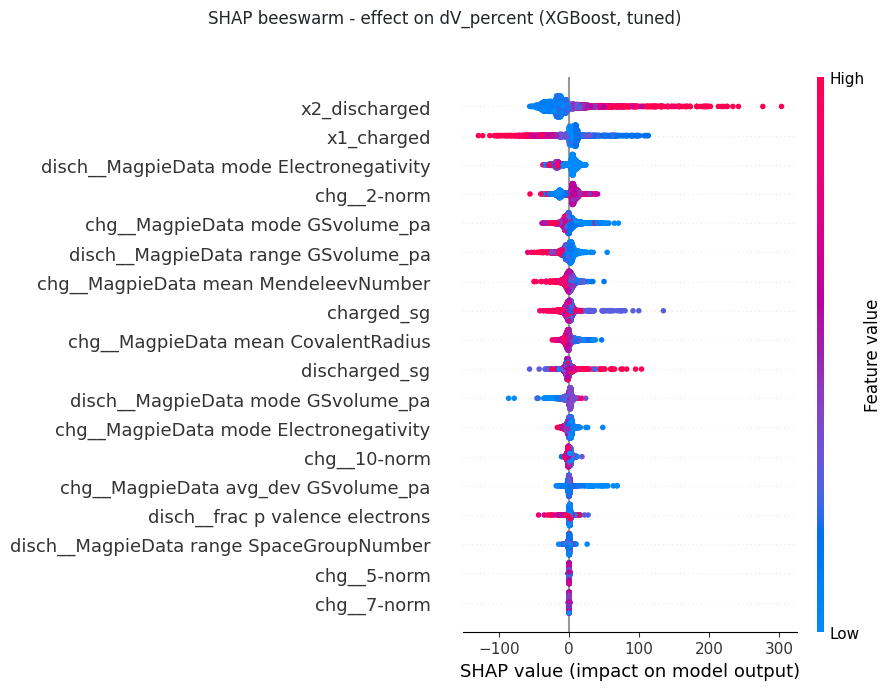

In [30]:
shap.plots.beeswarm(shap_values, max_display=20, show=False)

fig = plt.gcf()
fig.set_size_inches(9, 7)
fig.suptitle(f"SHAP beeswarm - effect on {TARGET} "
             f"({short_names([shap_name])[0]}, tuned)", fontsize=12, color=TEXT)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

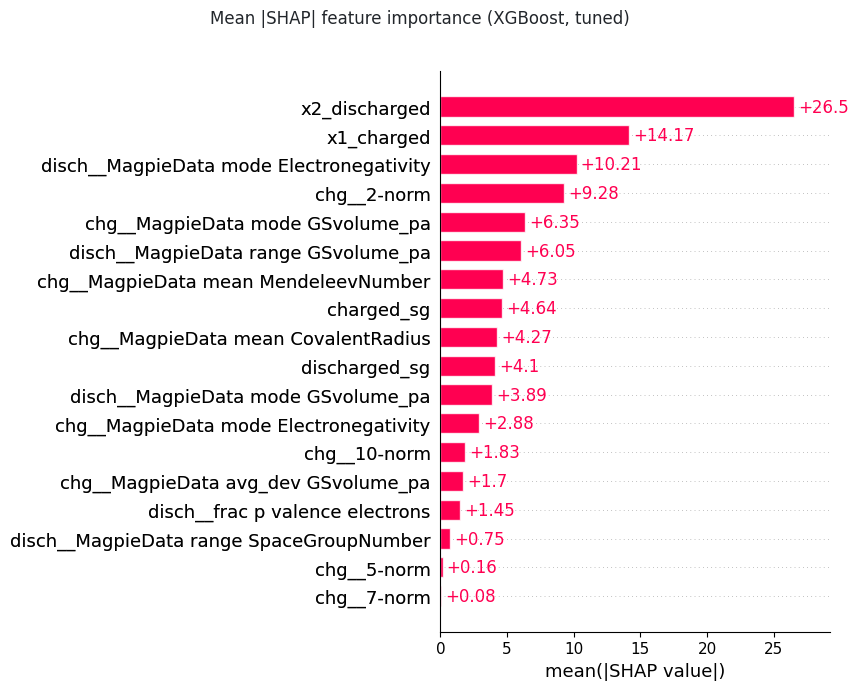

Top 15 features by mean |SHAP|
x2_discharged                               26.500731
x1_charged                                  14.174830
disch__MagpieData mode Electronegativity    10.213920
chg__2-norm                                  9.281350
chg__MagpieData mode GSvolume_pa             6.345630
disch__MagpieData range GSvolume_pa          6.045430
chg__MagpieData mean MendeleevNumber         4.725570
charged_sg                                   4.642490
chg__MagpieData mean CovalentRadius          4.266660
discharged_sg                                4.096140
disch__MagpieData mode GSvolume_pa           3.892130
chg__MagpieData mode Electronegativity       2.880520
chg__10-norm                                 1.831260
chg__MagpieData avg_dev GSvolume_pa          1.703410
disch__frac p valence electrons              1.449430


In [31]:
shap.plots.bar(shap_values, max_display=20, show=False)

fig = plt.gcf()
fig.set_size_inches(8.5, 7)
fig.suptitle(f"Mean |SHAP| feature importance "
             f"({short_names([shap_name])[0]}, tuned)", fontsize=12, color=TEXT)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

mean_abs_shap = (
    pd.Series(np.abs(shap_values.values).mean(axis=0), index=X_shap.columns,
              name="mean |SHAP|")
    .sort_values(ascending=False)
)
print("Top 15 features by mean |SHAP|")
print(mean_abs_shap.head(15).round(5).to_string())

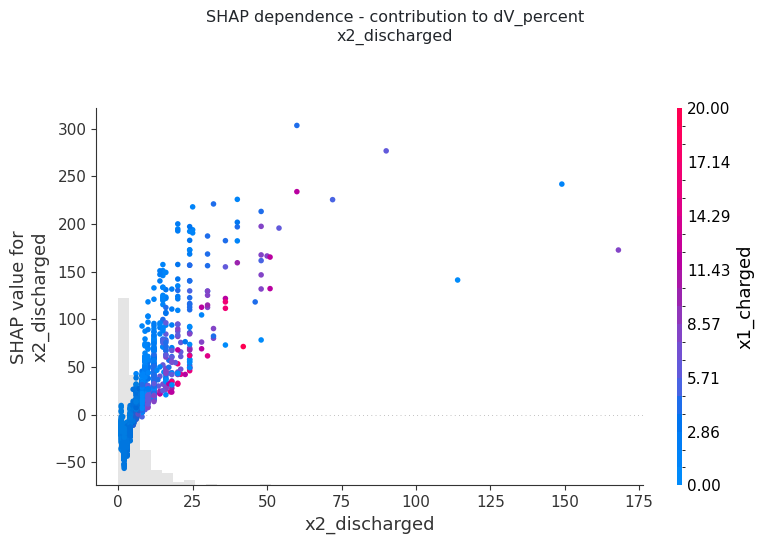

In [32]:
top_feature = mean_abs_shap.index[0]

shap.plots.scatter(shap_values[:, top_feature], color=shap_values, show=False)

fig = plt.gcf()
fig.set_size_inches(8, 5.5)
fig.suptitle(f"SHAP dependence - contribution to {TARGET}\n{top_feature}",
             fontsize=11.5, color=TEXT)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

# Partial Dependence

model    : XGBoost (boosting)
rows     : 5,000
features :
  1. x2_discharged  (mean |SHAP| = 26.5007)
  2. x1_charged  (mean |SHAP| = 14.1748)
  3. disch__MagpieData mode Electronegativity  (mean |SHAP| = 10.2139)
  4. chg__2-norm  (mean |SHAP| = 9.2814)
  5. chg__MagpieData mode GSvolume_pa  (mean |SHAP| = 6.3456)


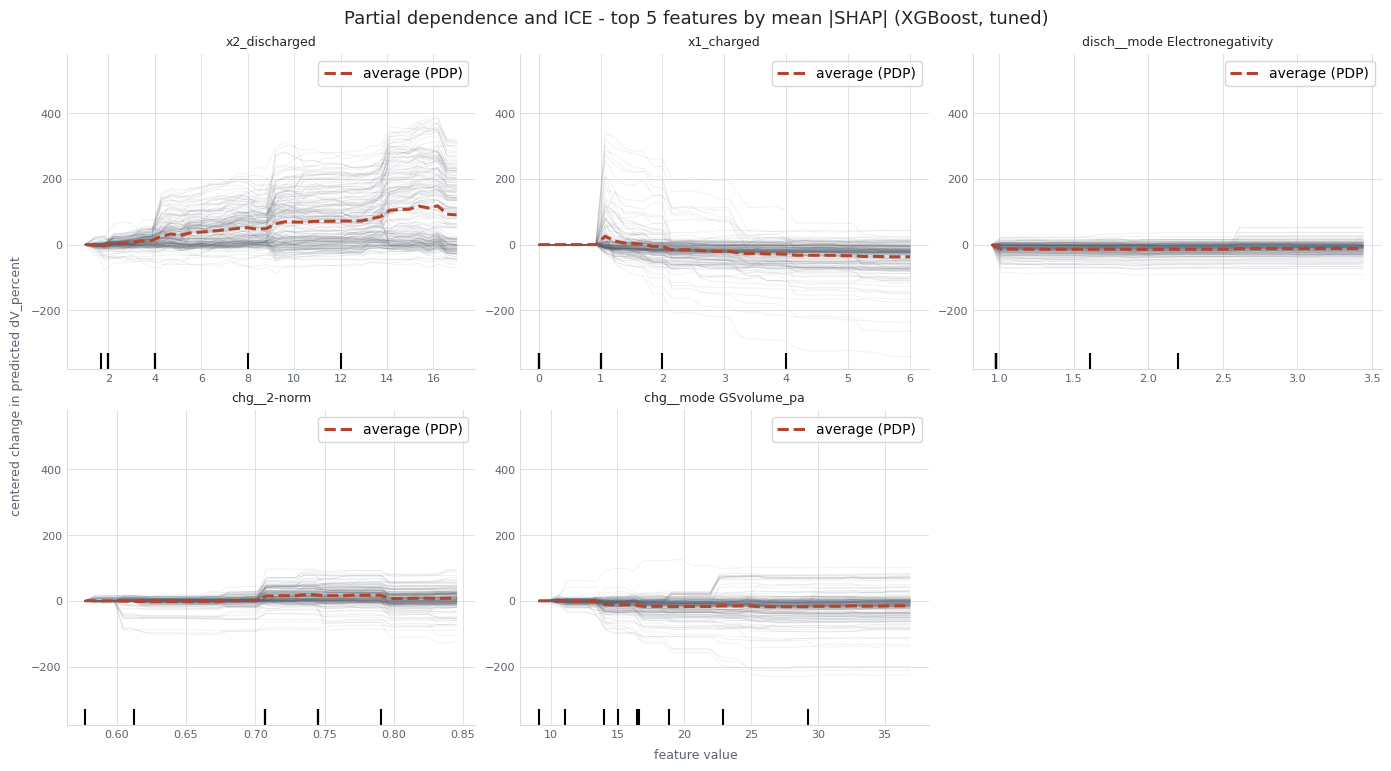

In [33]:
# Note: PDP evaluates feature combinations that may not occur in the data, and
# the Magpie features are strongly correlated.
pdp_features = [f for f in mean_abs_shap.index if f not in onehot_cols][:PDP_TOP_N]

rng_pdp = np.random.RandomState(RANDOM_STATE)
pdp_idx = rng_pdp.choice(len(X_test_enc), size=min(PDP_SAMPLE, len(X_test_enc)),
                         replace=False)
X_pdp = X_test_enc.iloc[pdp_idx]

print(f"model    : {shap_name}")
print(f"rows     : {len(X_pdp):,}")
print("features :")
for rank, name in enumerate(pdp_features, 1):
    print(f"  {rank}. {name}  (mean |SHAP| = {mean_abs_shap[name]:.4f})")

ncol = min(3, len(pdp_features))
nrow = (len(pdp_features) + ncol - 1) // ncol
fig, axes = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, 3.8 * nrow),
                         layout="constrained")
axes = np.atleast_1d(axes).ravel()

PartialDependenceDisplay.from_estimator(
    shap_model, X_pdp, features=pdp_features, kind="both",
    subsample=PDP_ICE_LINES, centered=True, grid_resolution=40,
    random_state=RANDOM_STATE, ax=axes[:len(pdp_features)],
    ice_lines_kw={"color": SPINE, "alpha": 0.10, "linewidth": 0.6},
    pd_line_kw={"color": BASE_COLOR, "linewidth": 2.2, "label": "average (PDP)"},
)

for ax, name in zip(axes, pdp_features):
    ax.set_title(truncate(name.replace("MagpieData ", "")), fontsize=9, color=TEXT)
    ax.set_xlabel("")
    ax.set_ylabel("")
    style_axes(ax, grid_axis="both")

for ax in axes[len(pdp_features):]:
    ax.axis("off")

fig.supxlabel("feature value", fontsize=9, color=SPINE)
fig.supylabel(f"centered change in predicted {TARGET}", fontsize=9, color=SPINE)
fig.suptitle(f"Partial dependence and ICE - top {len(pdp_features)} features by mean "
             f"|SHAP| ({short_names([shap_name])[0]}, tuned)", fontsize=13, color=TEXT)
plt.show()

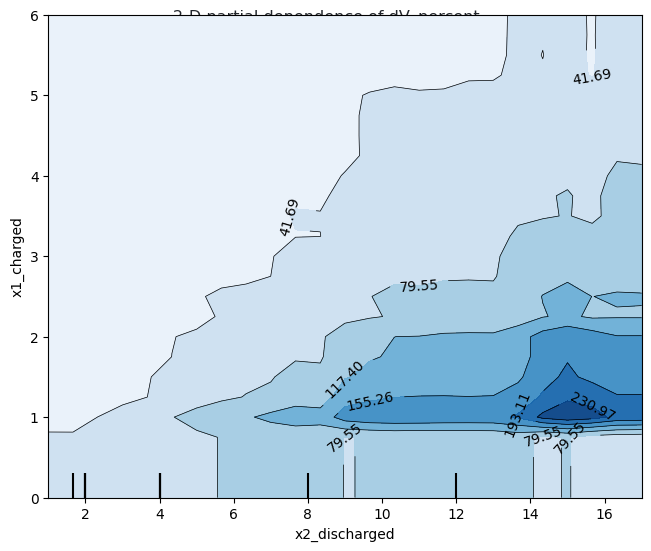

In [34]:
pair = pdp_features[:2]

fig, ax = plt.subplots(figsize=(6.4, 5.4), layout="constrained")

PartialDependenceDisplay.from_estimator(
    shap_model, X_pdp, features=[tuple(pair)], kind="average",
    grid_resolution=25, ax=ax,
    contour_kw={"cmap": DENSITY_CMAP, "alpha": 0.95},
)

labels = [p.replace("MagpieData ", "") for p in pair]
ax.set_xlabel(labels[0], fontsize=9, color=SPINE)
ax.set_ylabel(labels[1], fontsize=9, color=SPINE)
style_axes(ax, grid_axis="both")

ax.set_title(f"2-D partial dependence of {TARGET}\n{labels[0]} x {labels[1]}",
             fontsize=11.5, color=TEXT)
plt.show()

# Applicability Domain

model            : XGBoost (boosting)
descriptors p    : 18   train rows n : 674,540
warning leverage : h* = 0.00008
train leverage   : median 0.00002  max 0.02685

test rows inside the AD          : 162,637 (96.44%)
  structural outliers (h > h*)   : 3,792 (2.25%)
  response outliers (|sr| > 3)   : 2,428 (1.44%)
  both                           : 221


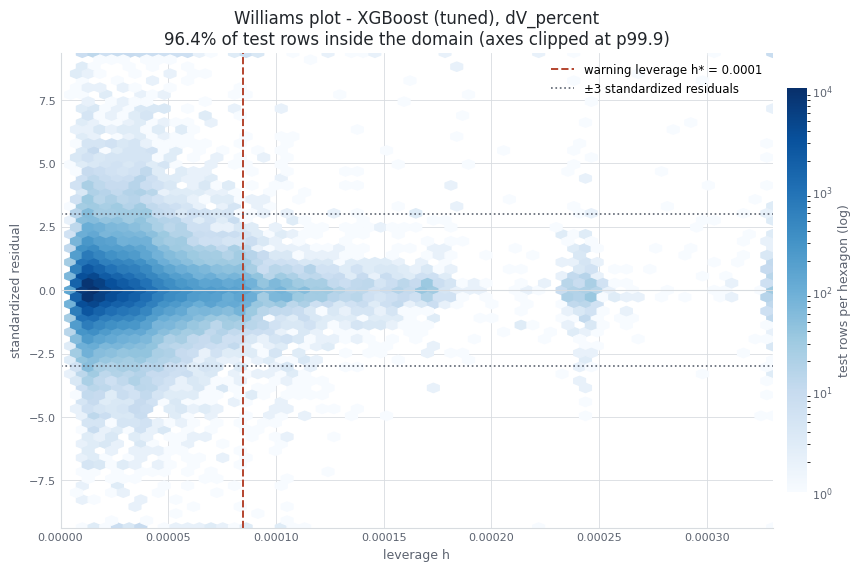

In [35]:
# Leverage h_i = z_i (Z^T Z)^-1 z_i^T with warning leverage h* = 3(p+1)/n.
# Z is standardized with training statistics; pinv handles the singular
# matrix produced by one-hot columns.
Z_train = X_train_enc.to_numpy(dtype=float)
Z_test = X_test_enc.to_numpy(dtype=float)

center = Z_train.mean(axis=0)
scale = Z_train.std(axis=0)
scale[scale == 0] = 1.0

Z_train = (Z_train - center) / scale
Z_test = (Z_test - center) / scale

gram_inv = np.linalg.pinv(Z_train.T @ Z_train)
leverage_train = np.einsum("ij,jk,ik->i", Z_train, gram_inv, Z_train)
leverage_test = np.einsum("ij,jk,ik->i", Z_test, gram_inv, Z_test)

n_train, p = Z_train.shape
h_star = 3 * (p + 1) / n_train

y_pred_ad = tuned_preds[shap_name]
residual = np.asarray(y_test) - y_pred_ad
std_residual = residual / residual.std()

outside_h = leverage_test > h_star
outside_r = np.abs(std_residual) > 3
inside = ~(outside_h | outside_r)

print(f"model            : {shap_name}")
print(f"descriptors p    : {p}   train rows n : {n_train:,}")
print(f"warning leverage : h* = {h_star:.5f}")
print(f"train leverage   : median {np.median(leverage_train):.5f}  "
      f"max {leverage_train.max():.5f}")
print()
print(f"test rows inside the AD          : {inside.sum():,} ({100 * inside.mean():.2f}%)")
print(f"  structural outliers (h > h*)   : {outside_h.sum():,} "
      f"({100 * outside_h.mean():.2f}%)")
print(f"  response outliers (|sr| > 3)   : {outside_r.sum():,} "
      f"({100 * outside_r.mean():.2f}%)")
print(f"  both                           : {(outside_h & outside_r).sum():,}")

fig, ax = plt.subplots(figsize=(8.5, 5.6), layout="constrained")

x_hi = np.quantile(leverage_test, 0.999)
y_lim = max(4.0, np.quantile(np.abs(std_residual), 0.999))
hexes = ax.hexbin(np.clip(leverage_test, 0, x_hi), np.clip(std_residual, -y_lim, y_lim),
                  gridsize=60, bins="log", cmap=DENSITY_CMAP, mincnt=1)

ax.axvline(h_star, color=BASE_COLOR, ls="--", lw=1.4,
           label=f"warning leverage h* = {h_star:.4f}")
ax.axhline(3, color=SPINE, ls=":", lw=1.2, label="±3 standardized residuals")
ax.axhline(-3, color=SPINE, ls=":", lw=1.2)
ax.axhline(0, color=GRID, lw=0.8)

ax.set_xlim(0, x_hi)
ax.set_ylim(-y_lim, y_lim)
ax.set_xlabel("leverage h", fontsize=9, color=SPINE)
ax.set_ylabel("standardized residual", fontsize=9, color=SPINE)
style_axes(ax, grid_axis="both")

bar = fig.colorbar(hexes, ax=ax, shrink=0.85, pad=0.02)
bar.set_label("test rows per hexagon (log)", color=SPINE, fontsize=9)
bar.ax.tick_params(colors=SPINE, labelsize=8, length=0)
bar.outline.set_visible(False)

ax.legend(loc="upper right", frameon=False, fontsize=8.5)
ax.set_title(f"Williams plot - {short_names([shap_name])[0]} (tuned), {TARGET}\n"
             f"{100 * inside.mean():.1f}% of test rows inside the domain "
             f"(axes clipped at p99.9)",
             fontsize=12, color=TEXT)
plt.show()

reference rows   : 50,000   k = 5
AD threshold     : 1.2339 (p95 of training distances)
test rows in AD  : 160,414 (95.12%)
test rows out    : 8,222 (4.88%)

Test performance by applicability domain (XGBoost (boosting))
                 rows     MAE     RMSE      R2
inside AD      160414  5.1623   8.4444  0.9818
outside AD       8222  9.9630  19.8421  0.9644
all test rows  168636  5.3964   9.3288  0.9798


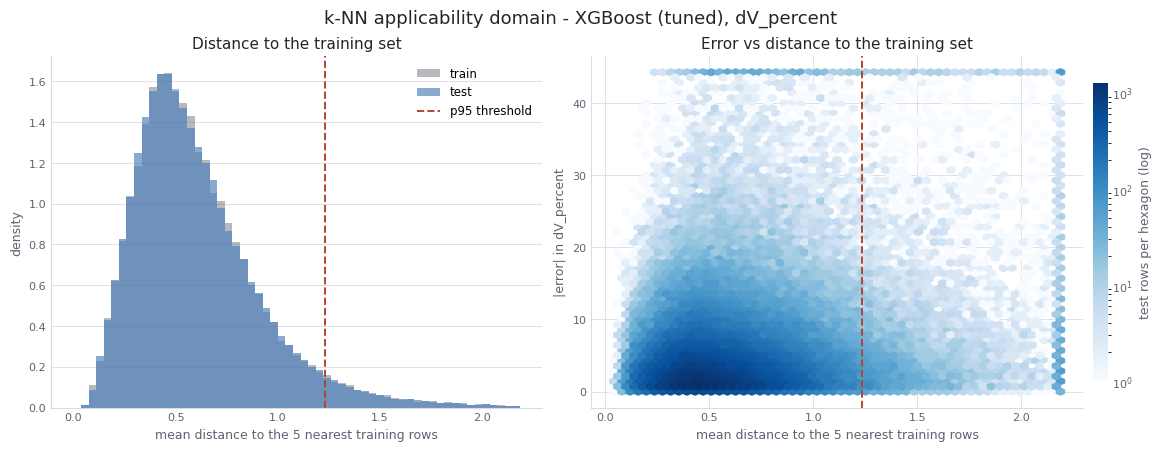

In [36]:
# Distance-based AD: a test row is out of domain when its mean distance to the
# k nearest training rows exceeds the AD_PERCENTILE of the training distances.
rng_ad = np.random.RandomState(RANDOM_STATE)
ref_idx = rng_ad.choice(n_train, size=min(AD_FIT_SAMPLE, n_train), replace=False)
Z_ref = Z_train[ref_idx]

neighbors = NearestNeighbors(n_neighbors=AD_KNN + 1).fit(Z_ref)

# skip the first neighbour of each reference row (the row itself)
dist_ref, _ = neighbors.kneighbors(Z_ref)
dist_ref = dist_ref[:, 1:].mean(axis=1)

dist_test, _ = neighbors.kneighbors(Z_test, n_neighbors=AD_KNN)
dist_test = dist_test.mean(axis=1)

ad_threshold = np.percentile(dist_ref, AD_PERCENTILE)
in_domain = dist_test <= ad_threshold

print(f"reference rows   : {len(Z_ref):,}   k = {AD_KNN}")
print(f"AD threshold     : {ad_threshold:.4f} (p{AD_PERCENTILE} of training distances)")
print(f"test rows in AD  : {in_domain.sum():,} ({100 * in_domain.mean():.2f}%)")
print(f"test rows out    : {(~in_domain).sum():,} ({100 * (~in_domain).mean():.2f}%)")

y_true_ad = np.asarray(y_test)
subsets = {
    "inside AD": in_domain,
    "outside AD": ~in_domain,
    "all test rows": np.ones_like(in_domain),
}
ad_summary = pd.DataFrame.from_dict({
    name: {
        "rows": mask.sum(),
        "MAE": mean_absolute_error(y_true_ad[mask], y_pred_ad[mask]),
        "RMSE": mean_squared_error(y_true_ad[mask], y_pred_ad[mask]) ** 0.5,
        "R2": r2_score(y_true_ad[mask], y_pred_ad[mask]),
    }
    for name, mask in subsets.items()
}, orient="index")

print(f"\nTest performance by applicability domain ({shap_name})")
print(ad_summary.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), layout="constrained")

ax = axes[0]
bins = np.linspace(0, np.quantile(dist_test, 0.995), 60)
ax.hist(dist_ref, bins=bins, color=SPINE, alpha=0.45, density=True, label="train")
ax.hist(dist_test, bins=bins, color=ACCENT, alpha=0.65, density=True, label="test")
ax.axvline(ad_threshold, color=BASE_COLOR, ls="--", lw=1.4,
           label=f"p{AD_PERCENTILE} threshold")
ax.set_xlabel(f"mean distance to the {AD_KNN} nearest training rows",
              fontsize=9, color=SPINE)
ax.set_ylabel("density", fontsize=9, color=SPINE)
ax.set_title("Distance to the training set", fontsize=11, color=TEXT)
ax.legend(frameon=False, fontsize=8.5)
style_axes(ax)

ax = axes[1]
abs_error = np.abs(residual)
hexes = ax.hexbin(np.clip(dist_test, 0, bins[-1]),
                  np.clip(abs_error, 0, np.quantile(abs_error, 0.995)),
                  gridsize=55, bins="log", cmap=DENSITY_CMAP, mincnt=1)
ax.axvline(ad_threshold, color=BASE_COLOR, ls="--", lw=1.4)
ax.set_xlabel(f"mean distance to the {AD_KNN} nearest training rows",
              fontsize=9, color=SPINE)
ax.set_ylabel(f"|error| in {TARGET}", fontsize=9, color=SPINE)
ax.set_title("Error vs distance to the training set", fontsize=11, color=TEXT)
style_axes(ax, grid_axis="both")

bar = fig.colorbar(hexes, ax=ax, shrink=0.85, pad=0.02)
bar.set_label("test rows per hexagon (log)", color=SPINE, fontsize=9)
bar.ax.tick_params(colors=SPINE, labelsize=8, length=0)
bar.outline.set_visible(False)

fig.suptitle(f"k-NN applicability domain - {short_names([shap_name])[0]} (tuned), "
             f"{TARGET}", fontsize=13, color=TEXT)
plt.show()